In [ ]:
import matplotlib
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib

path = "./toy_problem/"


# load all the images inside into 3d numpy array
def load_images(path):
    images = []
    for filename in sorted(os.listdir(path)):
        if filename.endswith(".png"):
            img = plt.imread(os.path.join(path, filename))
            # convert to grayscale
            img = np.mean(img, axis=2, dtype=np.float32) / 255.0
            images.append(img)
    return np.array(images)


# Load images
frames = load_images(path)
print(frames.shape)

# Animate the images using matplotlib and pause
plt.figure()
for i in range(frames.shape[0]):
    plt.imshow(frames[i], cmap="gray")
    plt.title(f"Frame {i + 1}")
    plt.axis("off")
    plt.pause(0.1)
plt.show()

#### Problem 2.1 - Low level gradient calculation: The most simple way is to approximate the gradient
as the difference between neighboring pixels/voxels.
In a 1D signal, x, this would be:
MATLAB: dx = x(2:end) - x(1:end-1)
PYTHON: dx = x[1:] - x[0:-1]
Obtain Vx,Vy,Vt for the entire volume and display for some selected frames.
Consider what happens with the image/volume size, when performing gradient calculations like this?

In [ ]:
frames.shape

In [ ]:
V = frames[1:, 1:, 1:] - frames[:-1, :-1, :-1]

# frame = V[50, :, :]
Vx_raw = frames[:, :, 1:] - frames[:, :, :-1]
Vy_raw = frames[:, 1:, :] - frames[:, :-1, :]
Vt_raw = frames[1:, :, :] - frames[:-1, :, :]

plt.figure()
plt.imshow(Vx_raw[50], cmap="gray")
plt.title("Optical Flow (Frame 1)")
plt.axis("off")
plt.show()

In [ ]:
frames[50].min()

In [ ]:
frame.min()

When performing such a gradient the dimensions dimnishes, definitely.
* Image size - decreases
* Volume size - well, you substract stuff, so that also gets smaller.
    * You actually end up with a range [-1,1] or [`-frame.max()`, `frame.max()`]

#### Problem 2.2

In [ ]:
import scipy

fig, ax = plt.subplots(nrows=1, ncols=4, figsize=(15, 5))
ax[0].imshow(
    scipy.ndimage.sobel(frames[50], mode="constant", cval=0.0, axis=0),
    cmap="gray",
)
ax[0].set_title("Sobel Filter (Axis 0)")

ax[1].imshow(
    scipy.ndimage.sobel(frames[50], mode="constant", cval=0.0, axis=1),
    cmap="gray",
)
ax[1].set_title("Sobel Filter (Axis 1)")

ax[2].imshow(
    scipy.ndimage.sobel(frames, mode="constant", cval=0.0, axis=0)[50],
    cmap="gray",
)
ax[2].set_title("Sobel Filter around time")

ax[3].imshow(frames[50], cmap="gray")
ax[3].set_title("Original Frame")
plt.show()

In [ ]:
plt.imshow(frames[])

In [ ]:
plt.imshow(frames[49] - frames[51], cmap="gray")

In [ ]:
# flipped sobel
plt.imshow(
    -scipy.ndimage.sobel(frames[50], mode="constant", cval=0.0, axis=0),
    cmap="gray",
)

Conclusions:
* axis=0, means horizontal kernel (alongside rows)
* axis=1 means vertical kernel (alongside columns)
* batching does not work (cannot do this with 3 at the same time haha, at least when the time is first)
* Flipping - for kernels like sobel and prewit, it's simply about taking a negative.
* To actually understand the underlying implementation - I would need to spend some time on the underlying logic.

### Problem 2.3

In [ ]:
# gaussian filter as derivative

fig, ax = plt.subplots(nrows=1, ncols=4, figsize=(15, 5))
ax[0].imshow(
    scipy.ndimage.gaussian_filter(
        frames, sigma=1, order=[0, 0, 1], mode="constant", cval=0.0
    )[50],
    cmap="gray",
)
ax[0].set_title("Gaussian Filter Vx (Axis 2)")

ax[1].imshow(
    scipy.ndimage.gaussian_filter(
        frames, sigma=1, order=[0, 1, 0], mode="constant", cval=0.0
    )[50],
    cmap="gray",
)
ax[1].set_title("Gaussian Filter Vy (Axis 1)")

ax[2].imshow(
    scipy.ndimage.gaussian_filter(
        frames, sigma=1, order=[1, 0, 0], mode="constant", cval=0.0
    )[50],
    cmap="gray",
)
ax[2].set_title("Gaussian Filter Vt (Axis 0 / time)")

ax[3].imshow(frames[50], cmap="gray")
ax[3].set_title("Original Frame")
plt.show()

### 3.1

In [ ]:
Vx = scipy.ndimage.gaussian_filter(frames, sigma=1, order=[0, 0, 1])
Vy = scipy.ndimage.gaussian_filter(frames, sigma=1, order=[0, 1, 0])
Vt = scipy.ndimage.gaussian_filter(frames, sigma=1, order=[1, 0, 0])

In [ ]:
# Simple:

t = 30
x, y = (100, 150)

N = 5


def get_region_around(x, y, N, arr):
    """Region centered around (x, y) with size NxN"""
    return arr[y - N : y + N + 1, x - N : x + N + 1]


Vx_region = get_region_around(x, y, N, Vx[t])
Vy_region = get_region_around(x, y, N, Vy[t])
Vt_region = get_region_around(x, y, N, Vt[t])

A = np.hstack((Vx_region.reshape(-1, 1), Vy_region.reshape(-1, 1)))
b = -Vt_region.reshape(-1, 1)
# Solve for the flow vector (u, v) using least squares
flow_vector, _, _, _ = np.linalg.lstsq(A, b)
# print("Estimated flow vector (u, v):", flow_vector

In [ ]:
# Plot the displacement vector on the original frame
plt.figure()
plt.imshow(frames[t], cmap="gray")
scaled_flow_vector = flow_vector.flatten() * 10  # Scale for better visualization
plt.quiver(
    x,
    y,
    scaled_flow_vector[0],
    scaled_flow_vector[1],
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1,
)
plt.title("Estimated Flow Vector")
plt.axis("off")
plt.show()

### To discuss
Edge strategy
I would apply this normalisation strategy - utilise only the data that is available (as the guy said in the video).
However, for now - let me go fast, and talk with William afterwards on how to do it.

In [ ]:
A.shape

### 3.2
APply to full volume

In [ ]:
# test 3d array
from pylab import dtype

arr = np.random.rand(3, 3, 3)
arr

In [ ]:
# go over all pixels in the frame, with a stride of 5, and compute the flow vector for each selected pixel and plot
t = 16
N = 11
stride = 20
plt.figure(figsize=(10, 10))
plt.imshow(frames[t], cmap="gray")
for y in range(N, frames[t].shape[0] - N, stride):
    for x in range(N, frames[t].shape[1] - N, stride):
        Vx_region = get_region_around(x, y, N, Vx[t])
        Vy_region = get_region_around(x, y, N, Vy[t])
        Vt_region = get_region_around(x, y, N, Vt[t])

        A = np.hstack((Vx_region.reshape(-1, 1), Vy_region.reshape(-1, 1)))
        b = -Vt_region.reshape(-1, 1)
        flow_vector, _, _, _ = np.linalg.lstsq(A, b)
        scaled_flow_vector = flow_vector.flatten() * 10
        plt.quiver(
            x,
            y,
            scaled_flow_vector[0],
            scaled_flow_vector[1],
            color="red",
            angles="xy",
            scale_units="xy",
            scale=1,
        )
plt.title("Estimated Flow Vectors")
plt.axis("off")
plt.show()

In [ ]:
# repeat for all frames (output all 64 images with flow vectors)

for t in range(frames.shape[0]):
    N = 3
    stride = 20
    plt.figure(figsize=(10, 10))
    plt.imshow(frames[t], cmap="gray")
    for y in range(N, frames[t].shape[0] - N, stride):
        for x in range(N, frames[t].shape[1] - N, stride):
            Vx_region = get_region_around(x, y, N, Vx[t])
            Vy_region = get_region_around(x, y, N, Vy[t])
            Vt_region = get_region_around(x, y, N, Vt[t])

            A = np.hstack((Vx_region.reshape(-1, 1), Vy_region.reshape(-1, 1)))
            b = -Vt_region.reshape(-1, 1)
            flow_vector, _, _, _ = np.linalg.lstsq(A, b)
            scaled_flow_vector = flow_vector.flatten() * 10
            plt.quiver(
                x,
                y,
                scaled_flow_vector[0],
                scaled_flow_vector[1],
                color="red",
                angles="xy",
                scale_units="xy",
                scale=1,
            )
    plt.title(f"Estimated Flow Vectors (Frame {t + 1})")
    plt.axis("off")
    plt.show()

In [ ]:
# repeat for all frames (output all 64 images with flow vectors)

for t in range(frames.shape[0]):
    N = 21
    stride = 20
    plt.figure(figsize=(10, 10))
    plt.imshow(frames[t], cmap="gray")
    for y in range(N, frames[t].shape[0] - N, stride):
        for x in range(N, frames[t].shape[1] - N, stride):
            Vx_region = get_region_around(x, y, N, Vx[t])
            Vy_region = get_region_around(x, y, N, Vy[t])
            Vt_region = get_region_around(x, y, N, Vt[t])

            A = np.hstack((Vx_region.reshape(-1, 1), Vy_region.reshape(-1, 1)))
            b = -Vt_region.reshape(-1, 1)
            flow_vector, _, _, _ = np.linalg.lstsq(A, b)
            scaled_flow_vector = flow_vector.flatten()
            if (
                np.linalg.norm(scaled_flow_vector) < 1
            ):  # Only plot significant flow vectors
                continue
            plt.quiver(
                x,
                y,
                scaled_flow_vector[0],
                scaled_flow_vector[1],
                color="red",
                angles="xy",
                scale_units="xy",
                scale=1,
            )
    plt.title(f"Estimated Flow Vectors (Frame {t + 1})")
    plt.axis("off")
    plt.show()

In [160]:
# super fast lucas-kanade

Vx2 = Vx * Vx
Vy2 = Vy * Vy
VxVy = Vx * Vy
VxVt = Vx * Vt
VyVt = Vy * Vt
s = 2
Sxx = scipy.ndimage.gaussian_filter(Vx2, sigma=s)
Syy = scipy.ndimage.gaussian_filter(Vy2, sigma=s)
Sxy = scipy.ndimage.gaussian_filter(VxVy, sigma=s)
Sxt = scipy.ndimage.gaussian_filter(VxVt, sigma=s)
Syt = scipy.ndimage.gaussian_filter(VyVt, sigma=s)

det = Sxx * Syy - Sxy * Sxy
u = -(Sxt * Syy - Syt * Sxy) / det
v = -(Sxx * Syt - Sxy * Sxt) / det


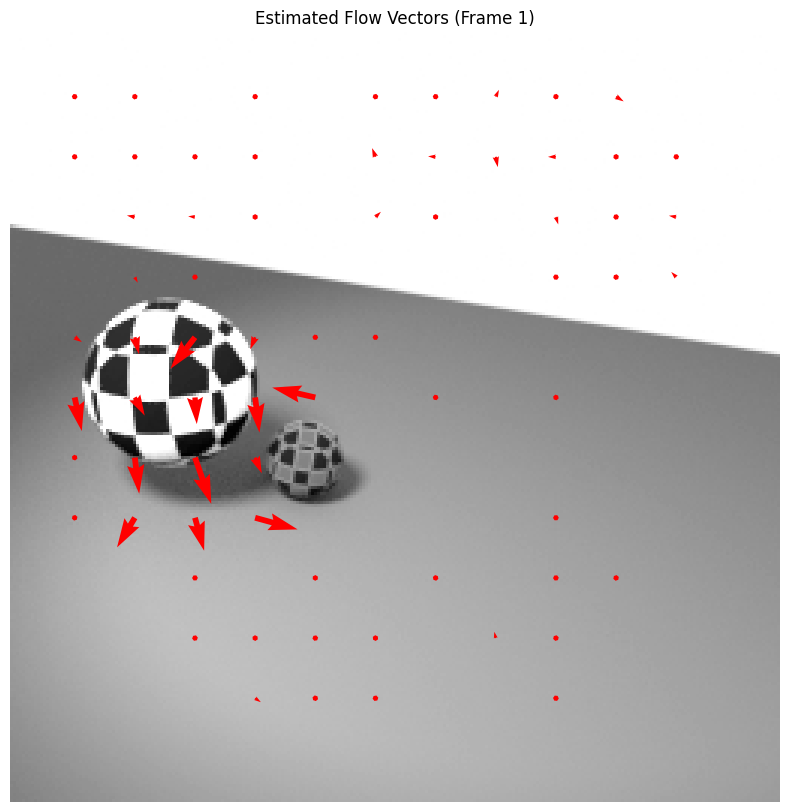

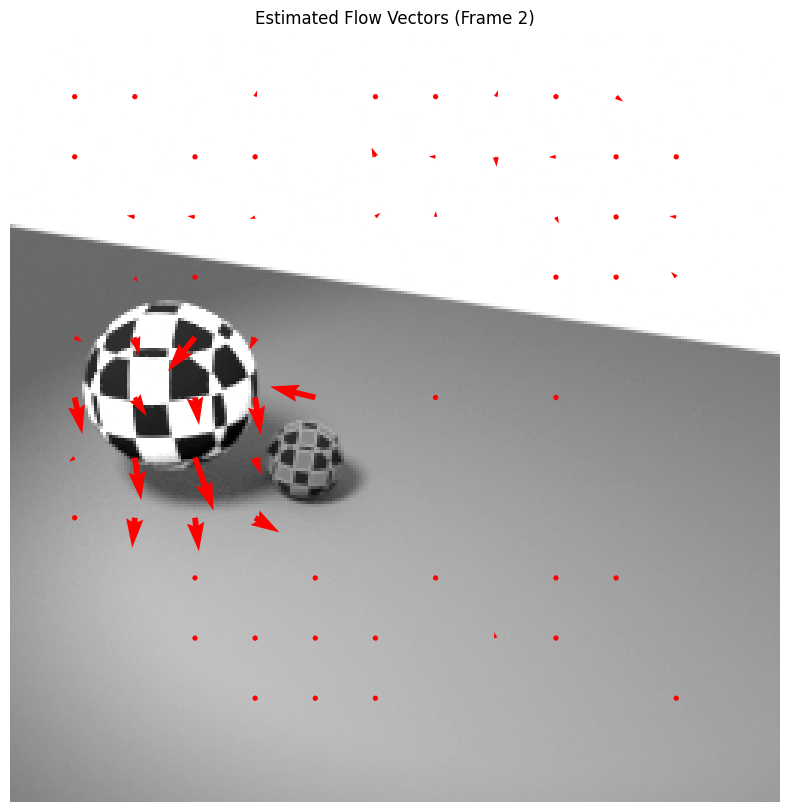

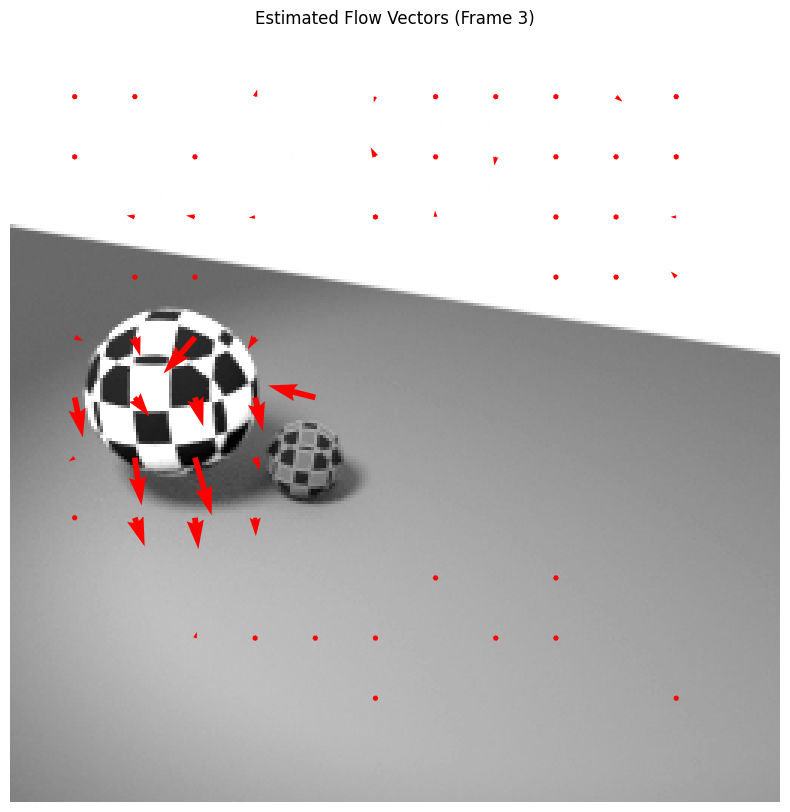

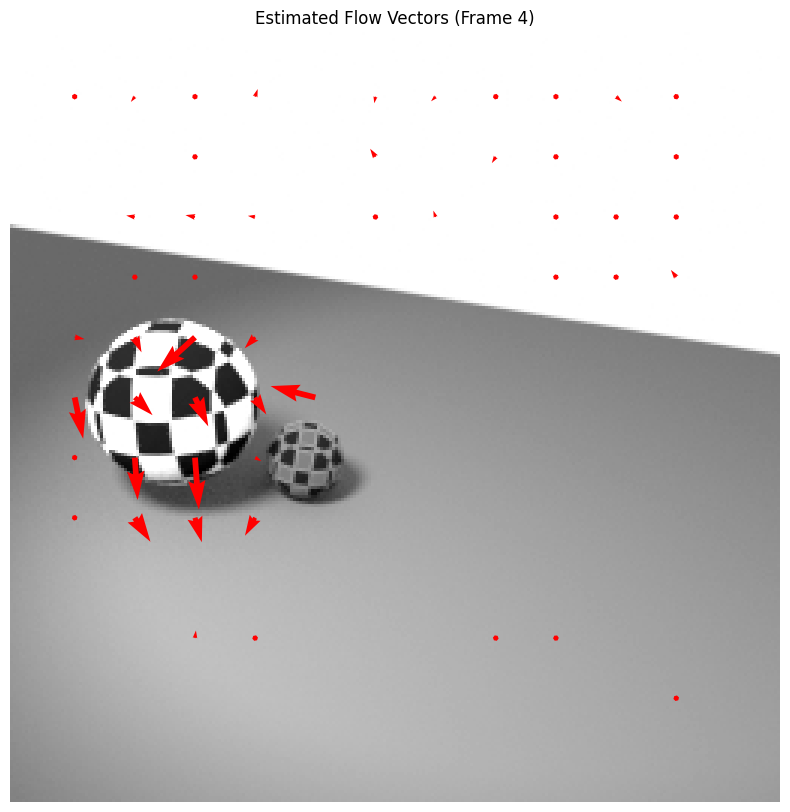

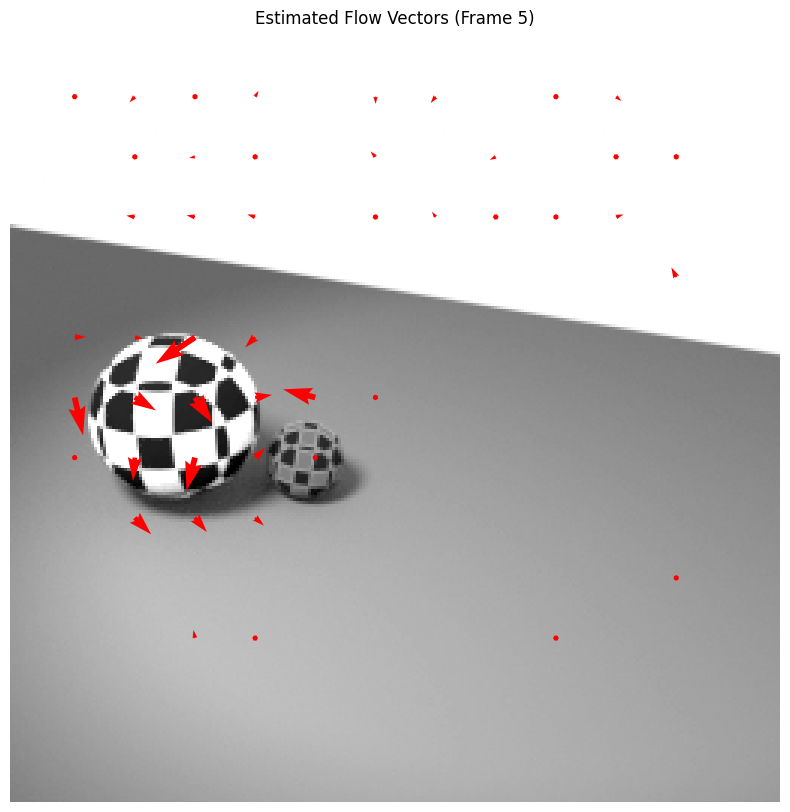

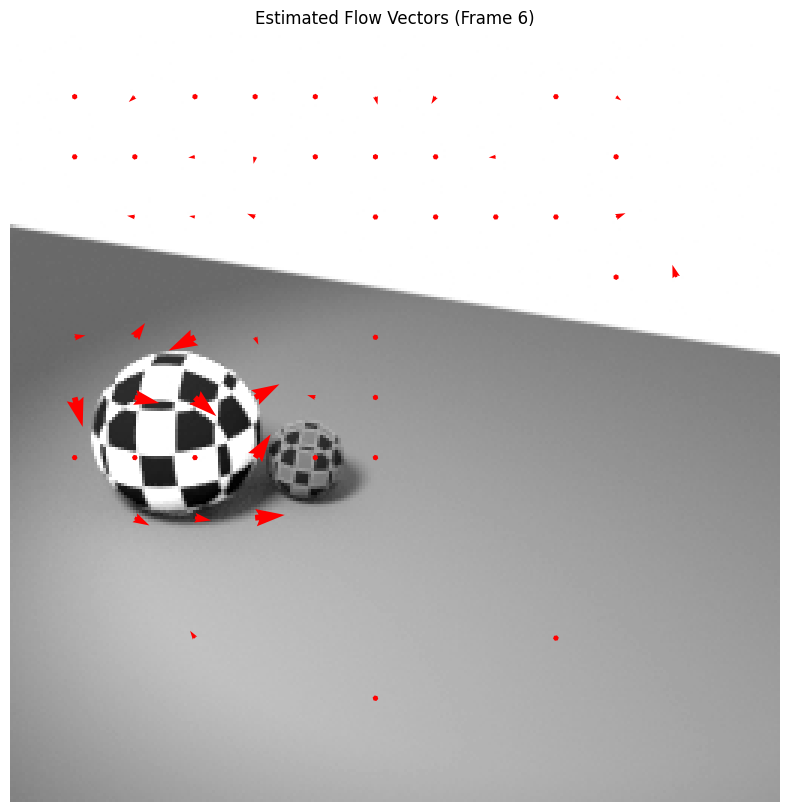

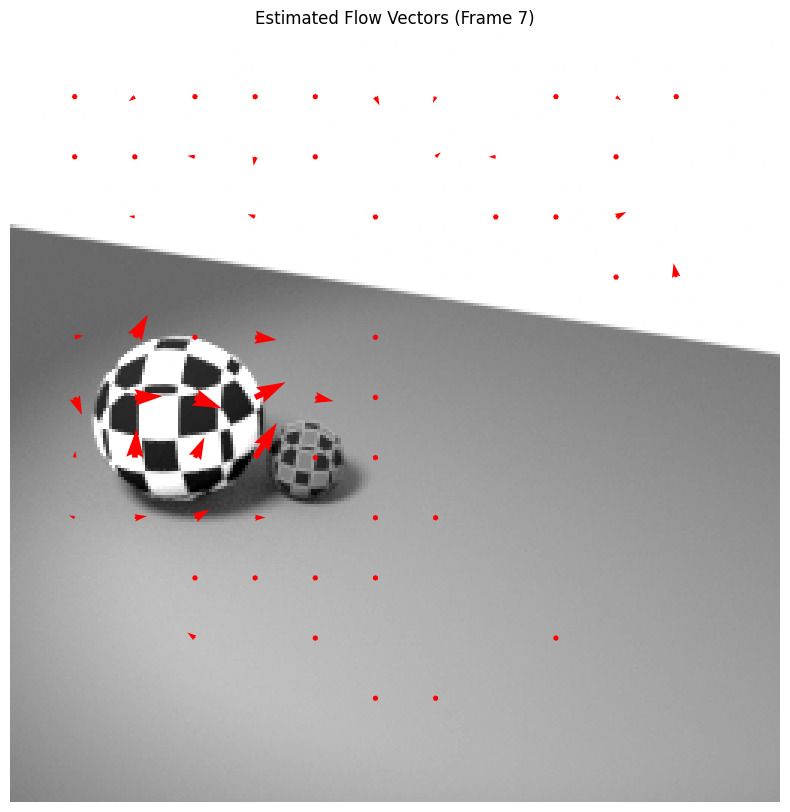

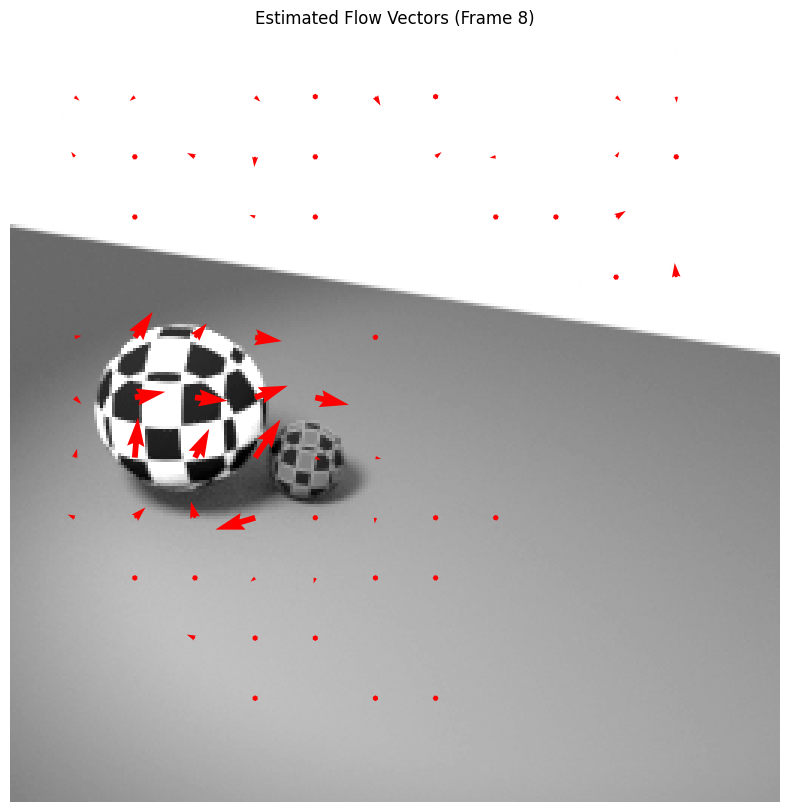

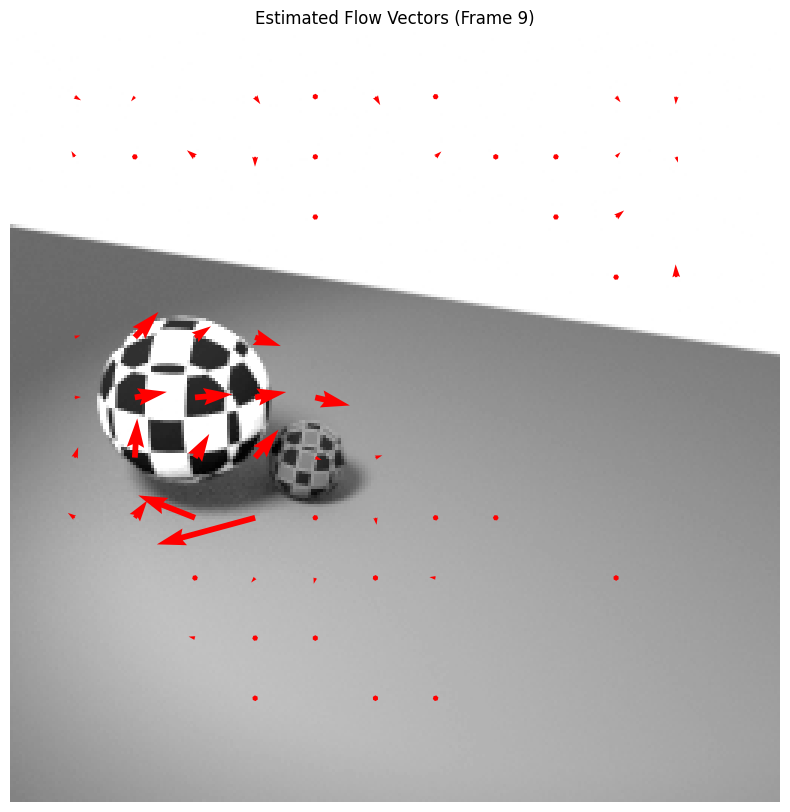

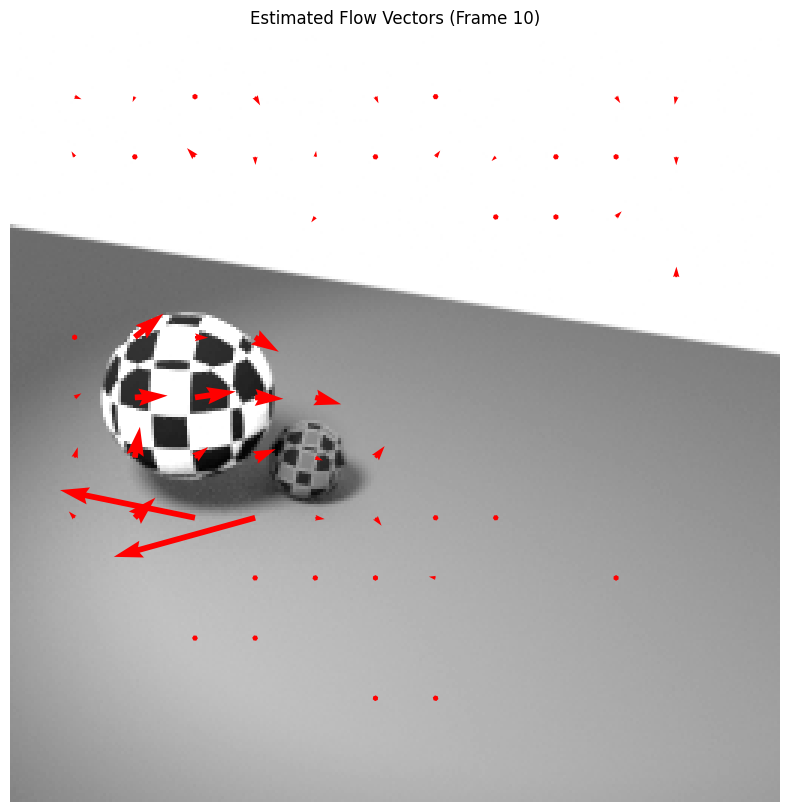

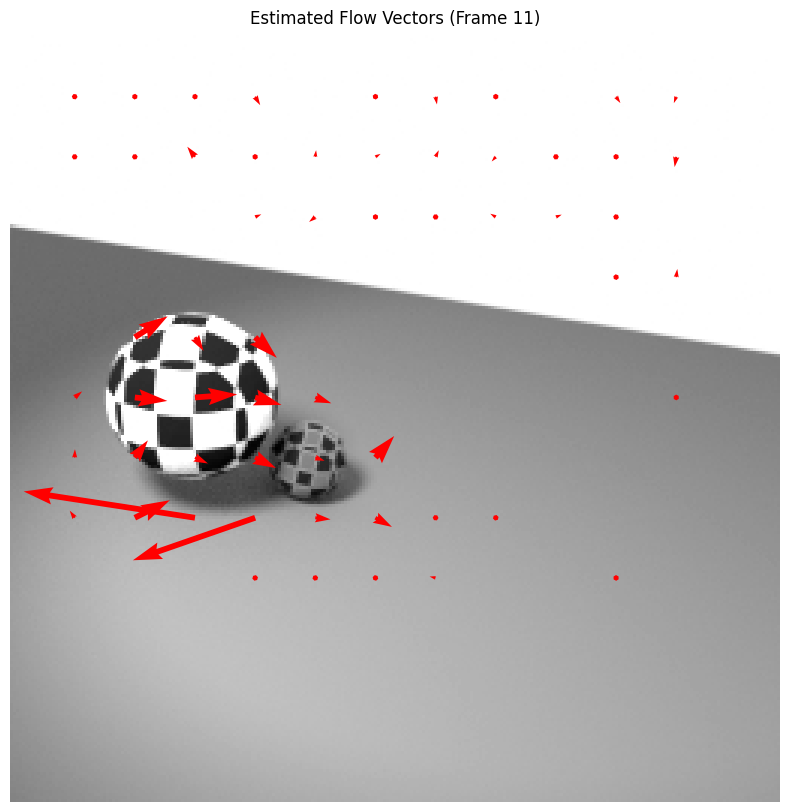

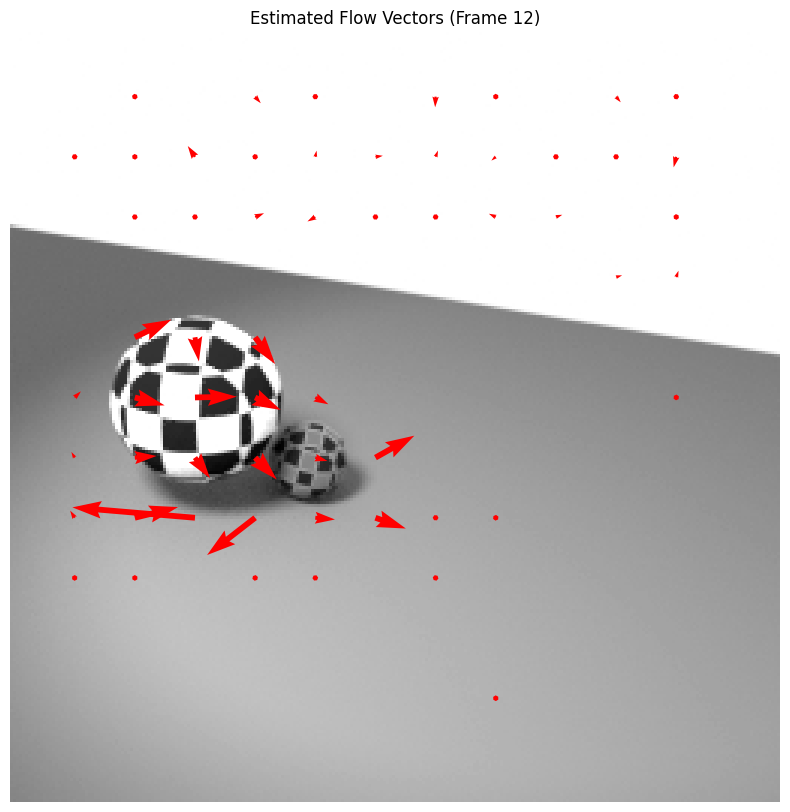

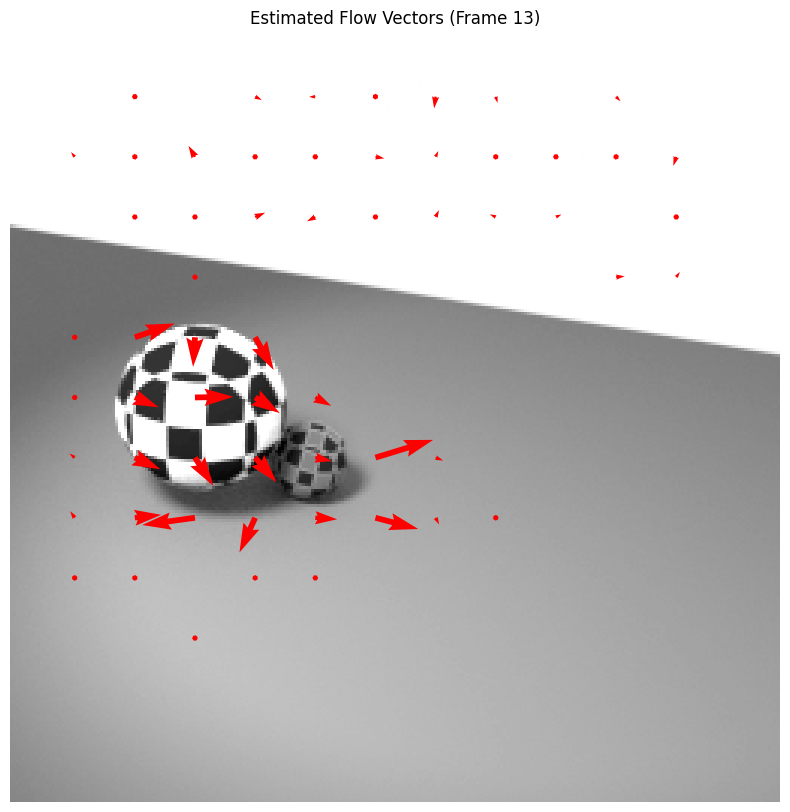

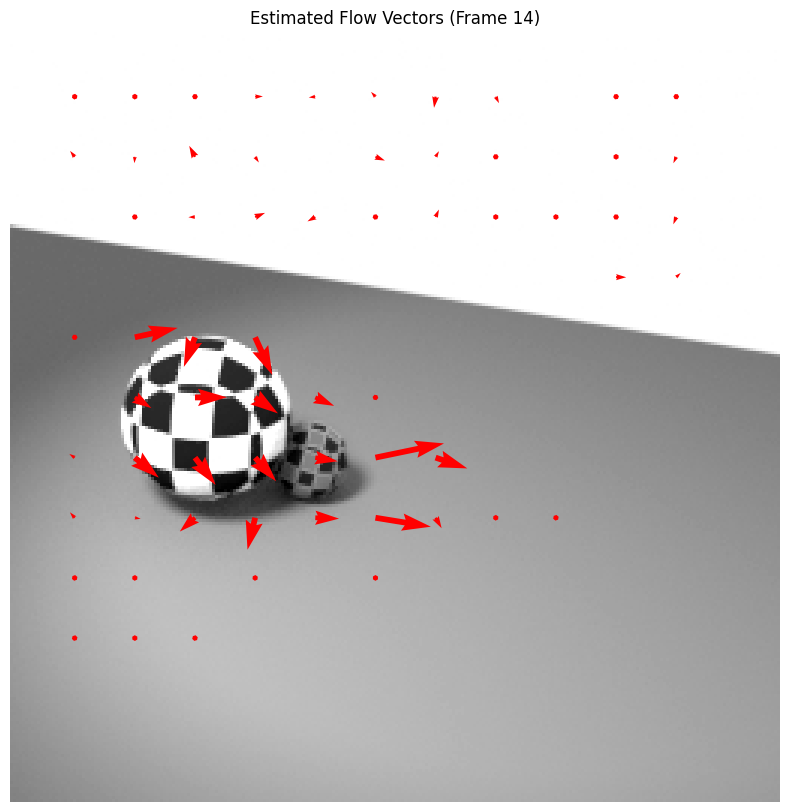

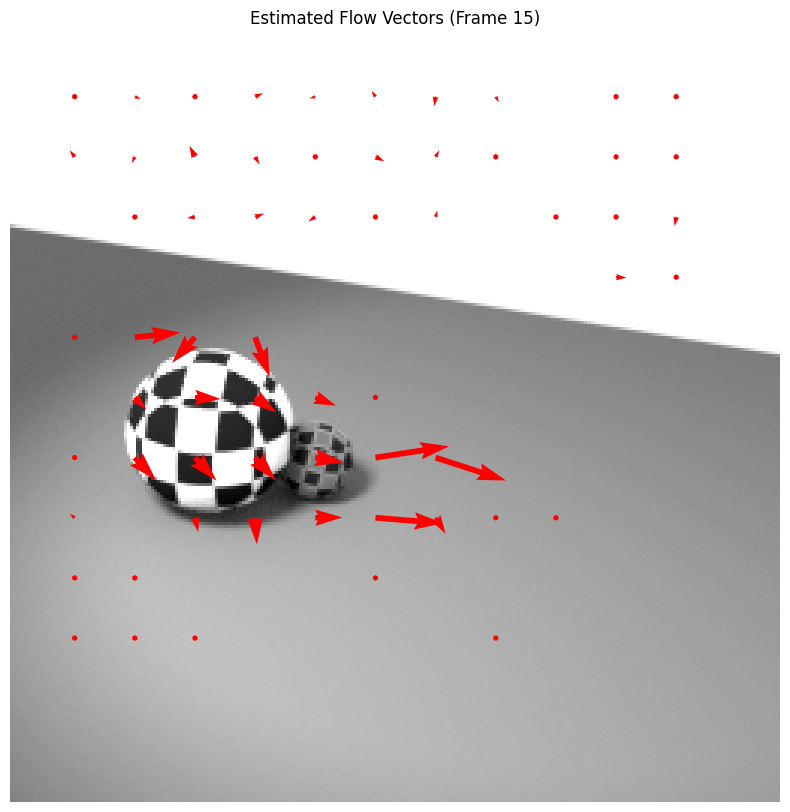

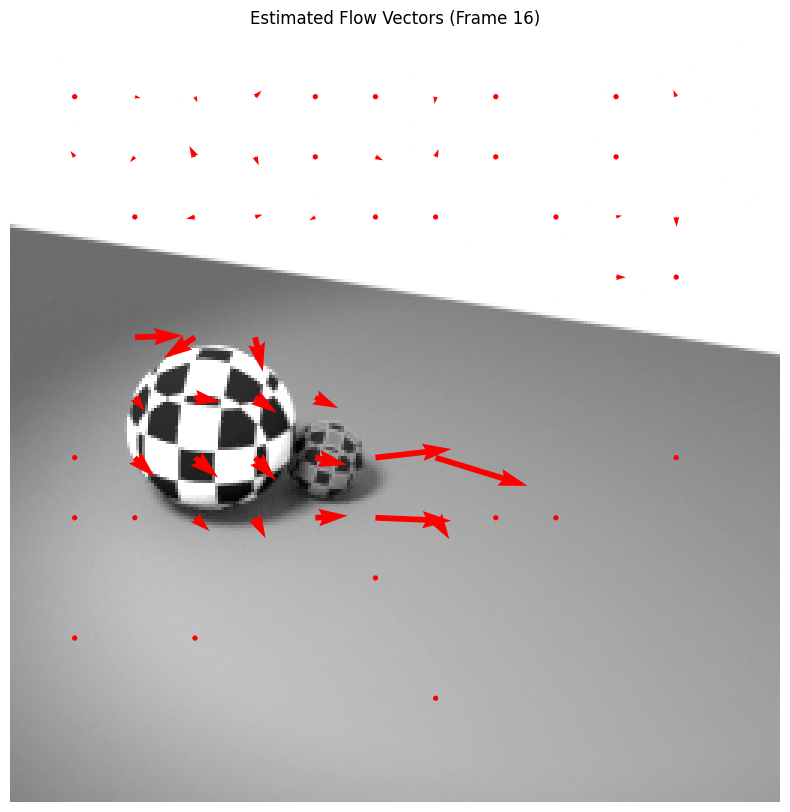

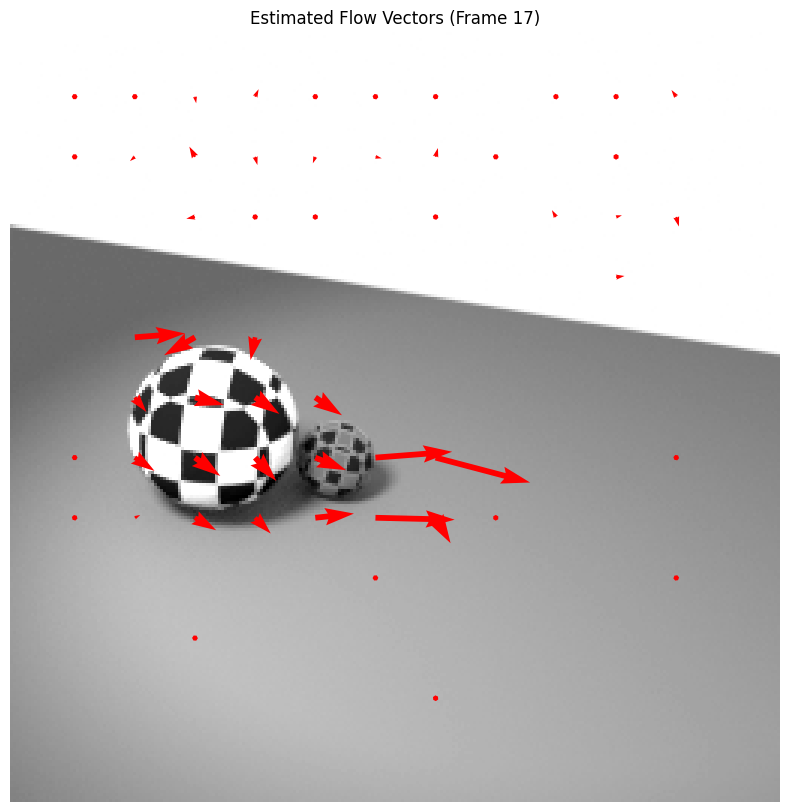

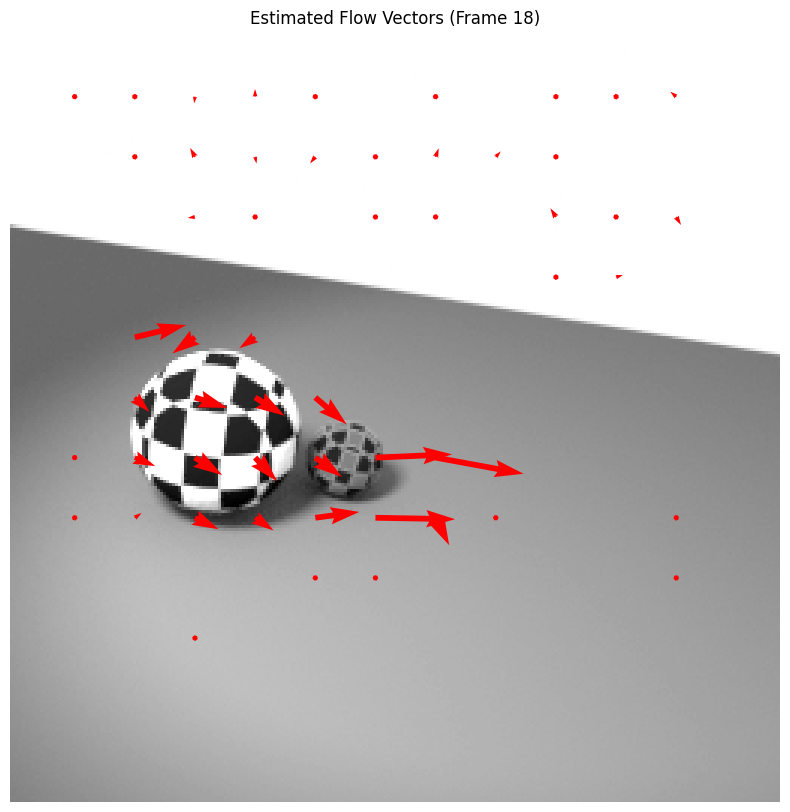

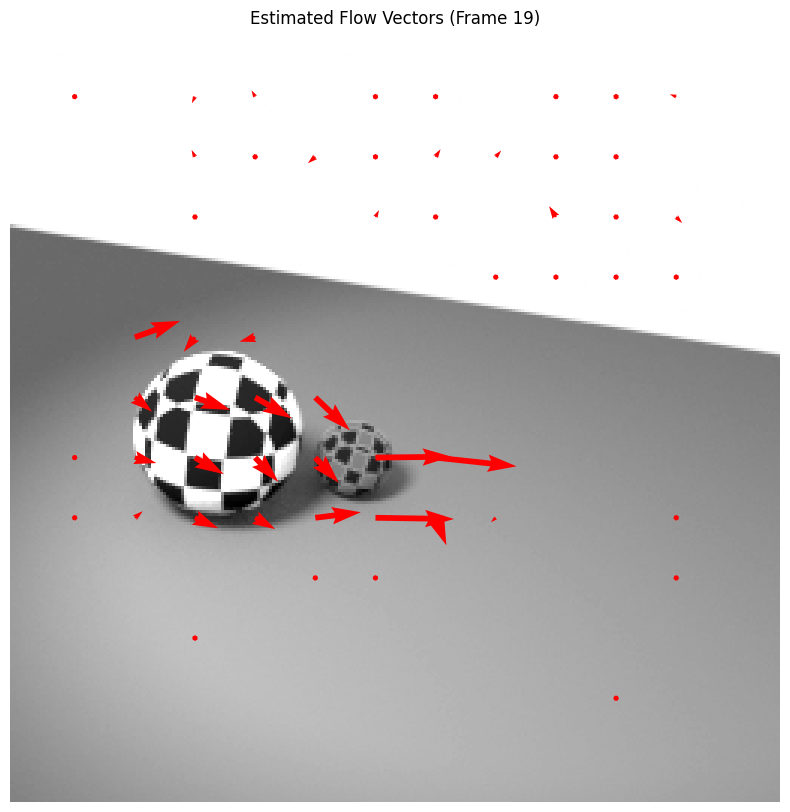

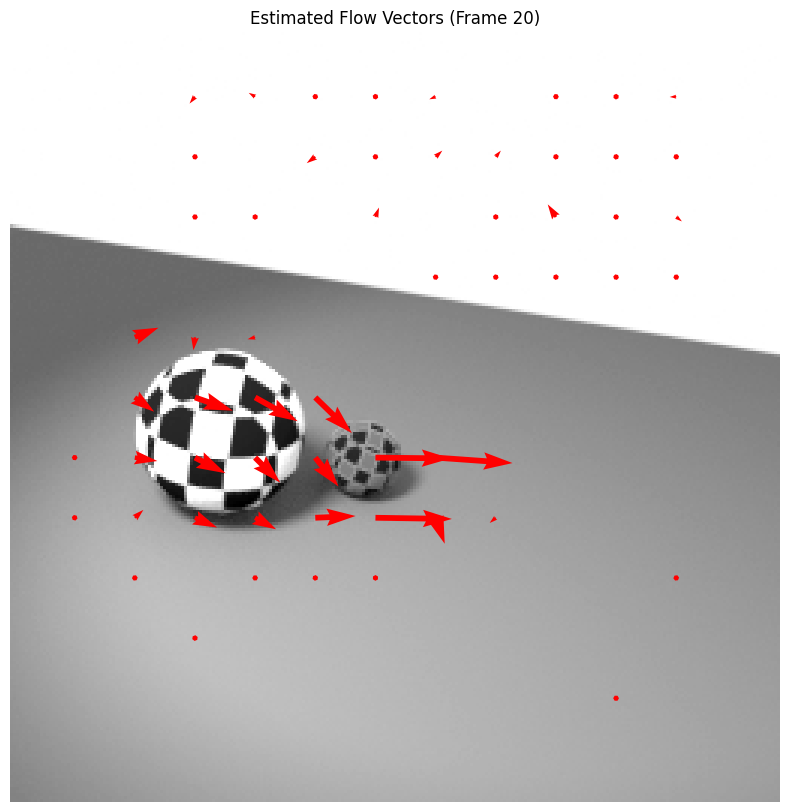

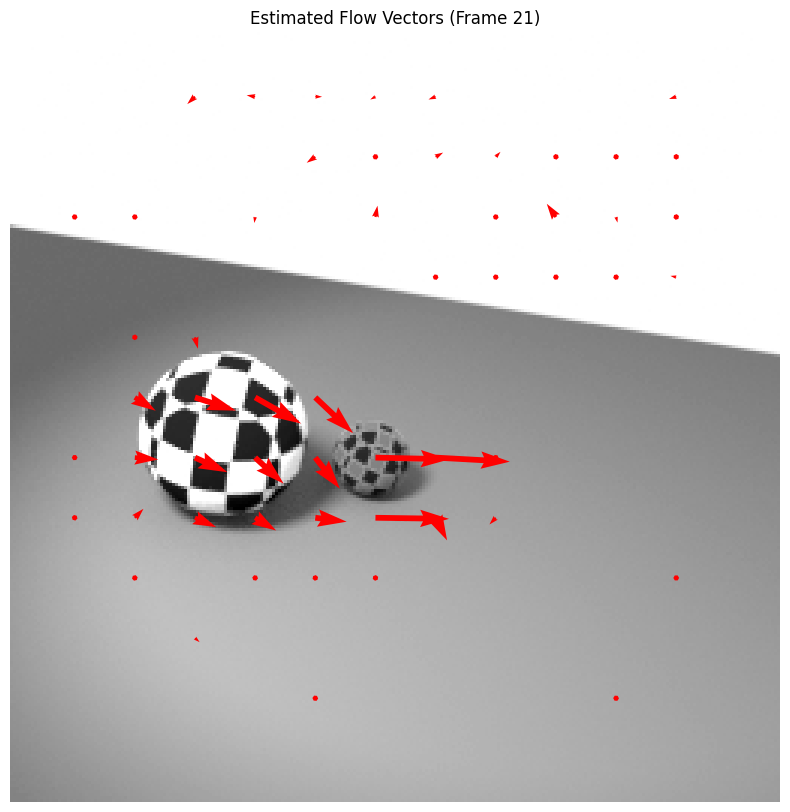

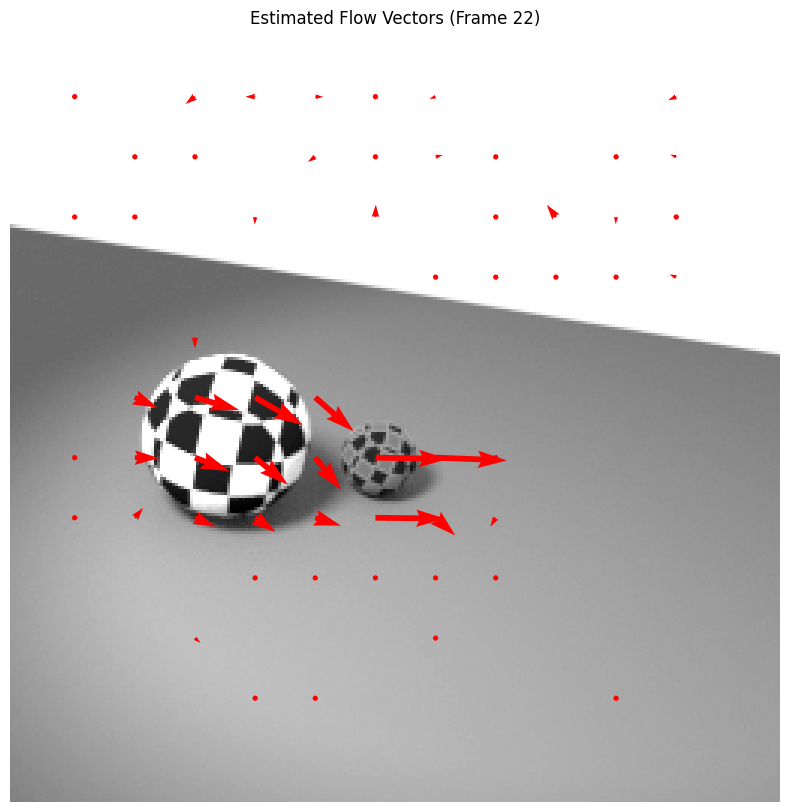

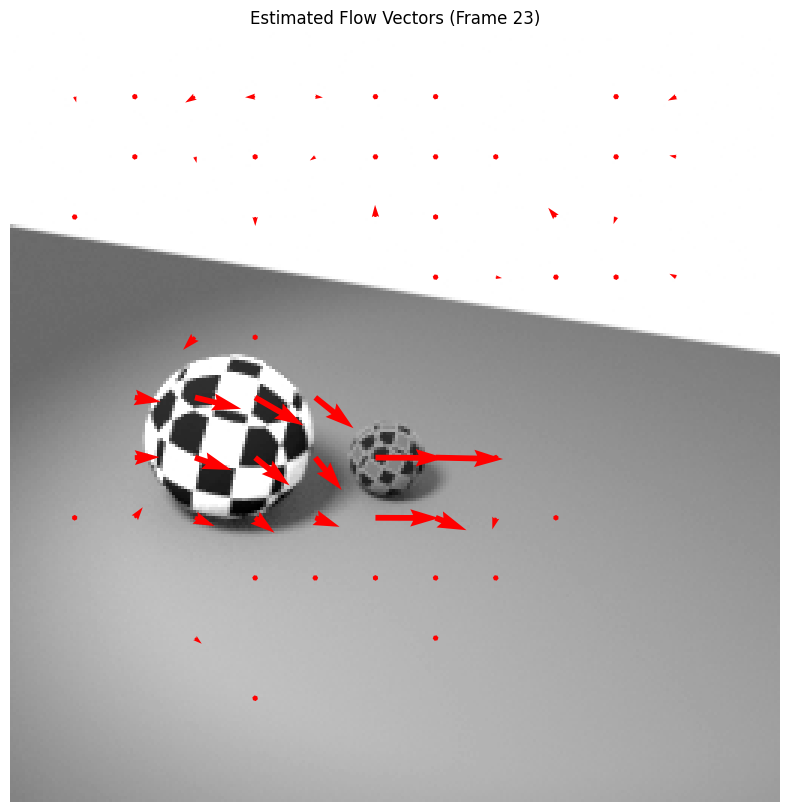

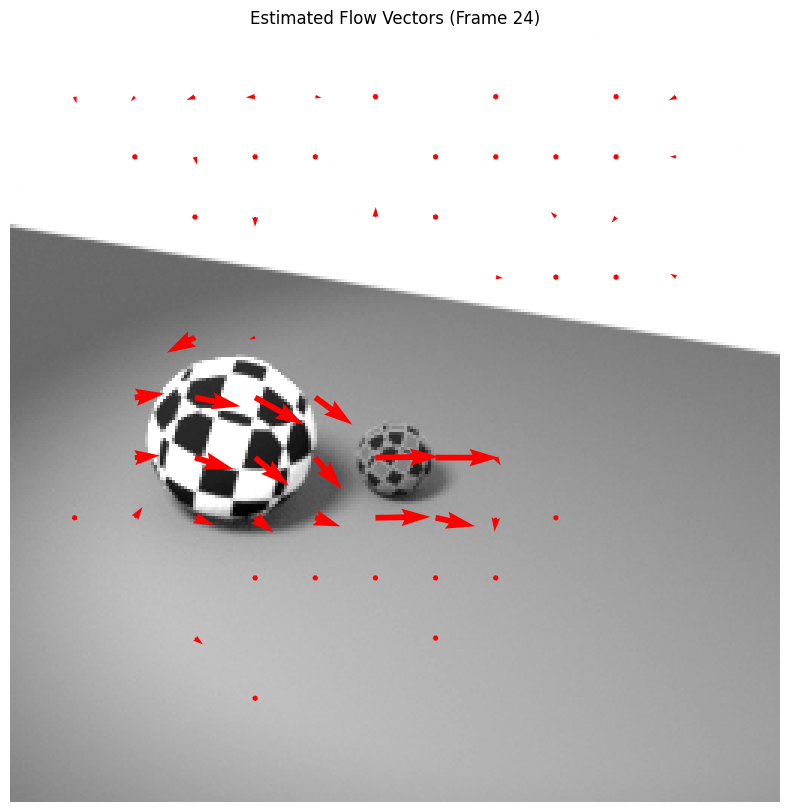

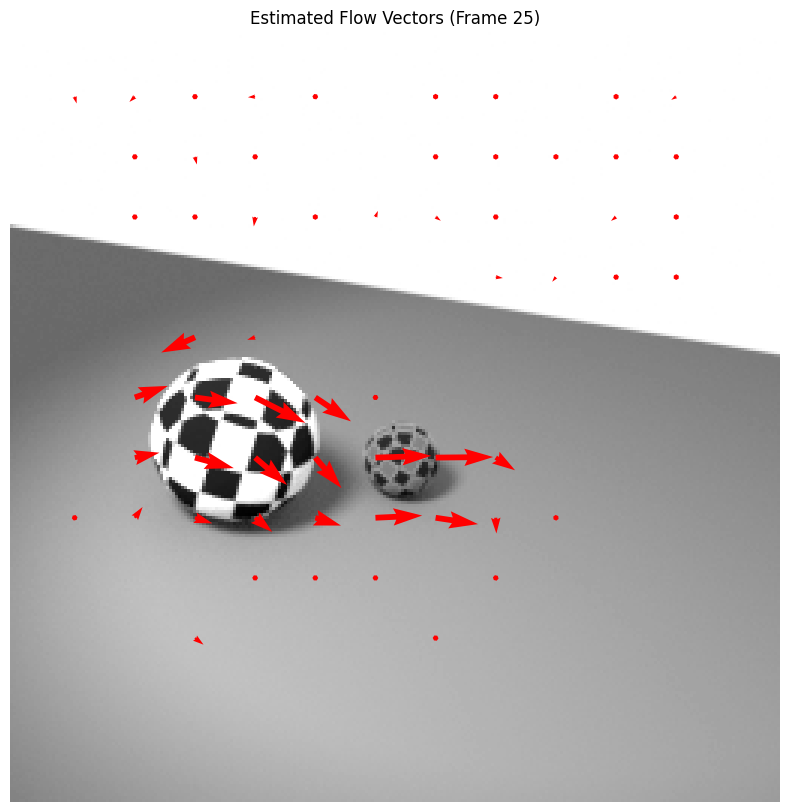

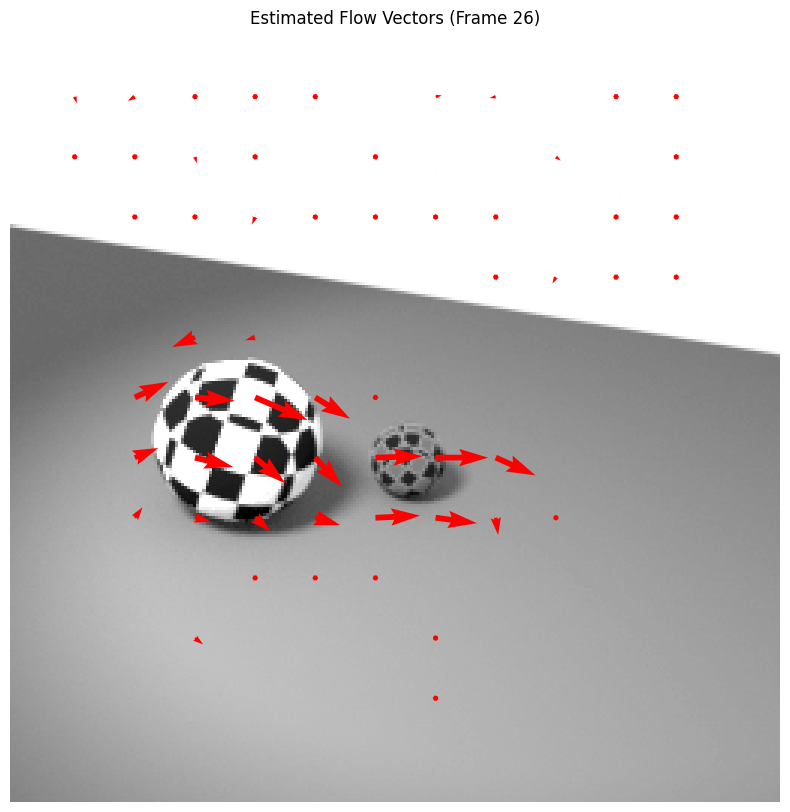

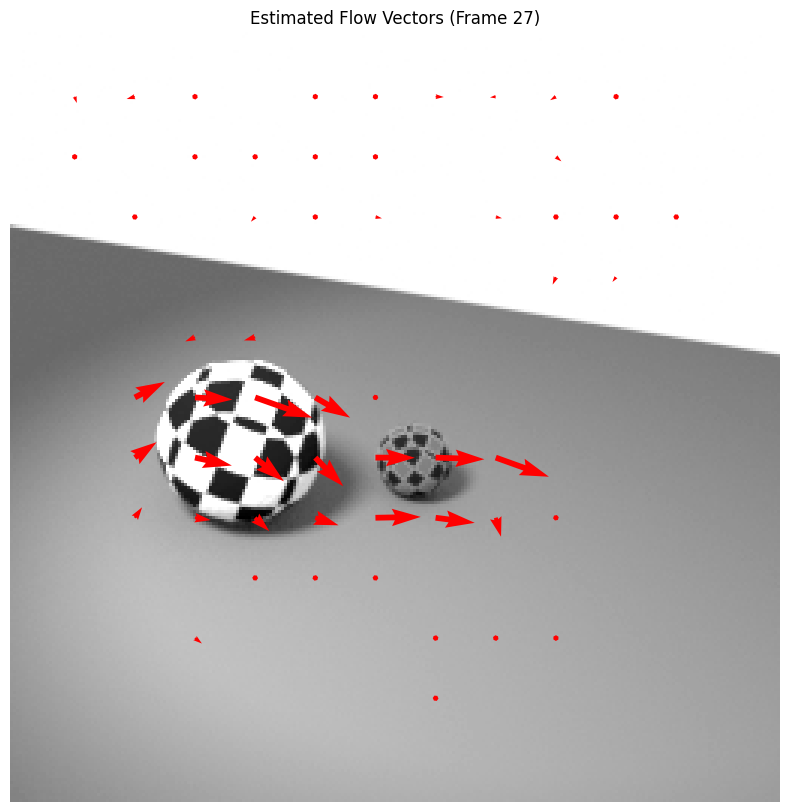

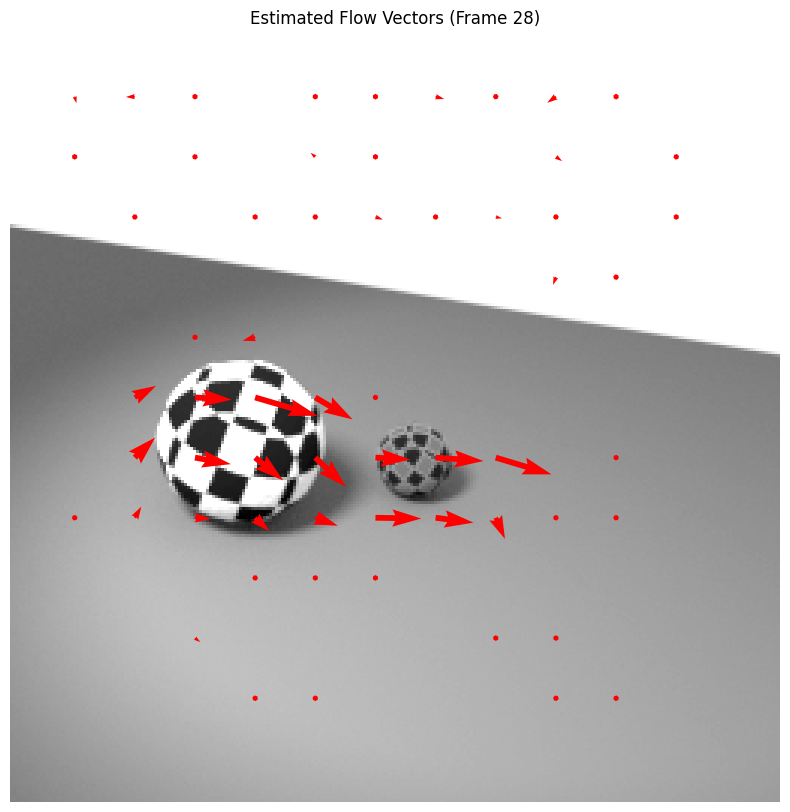

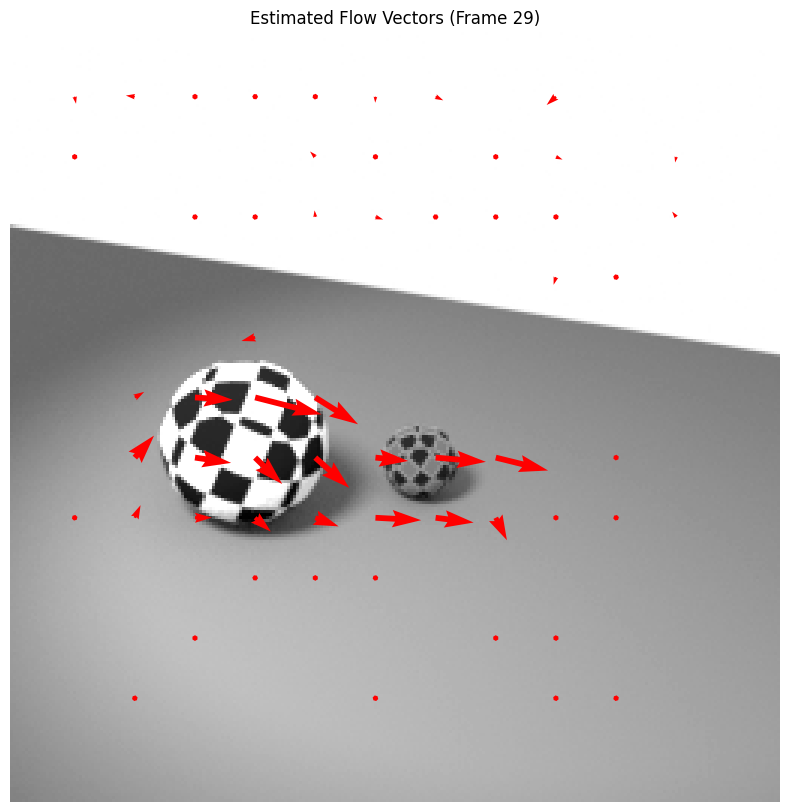

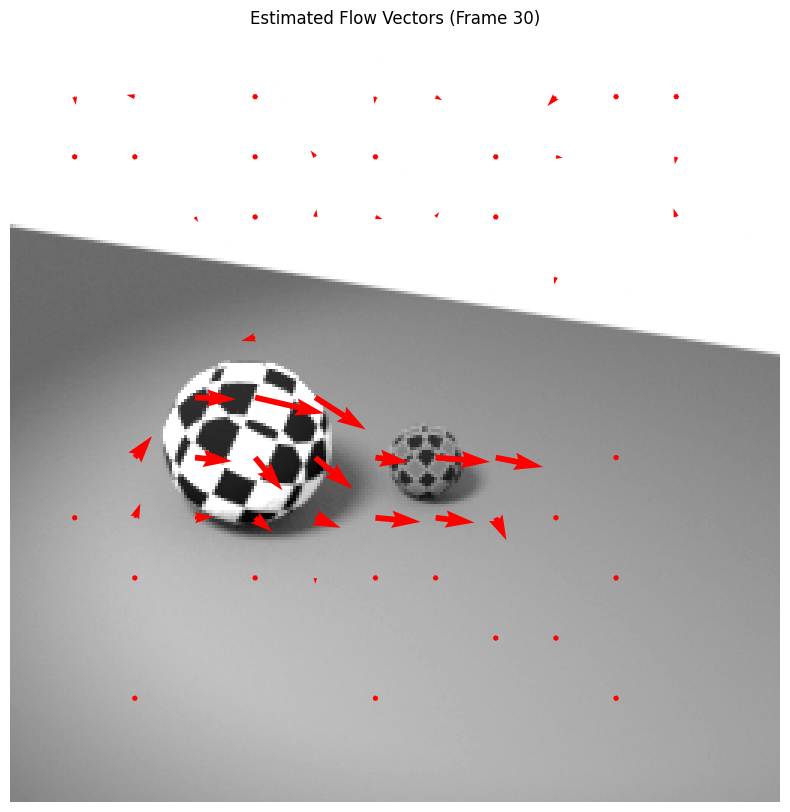

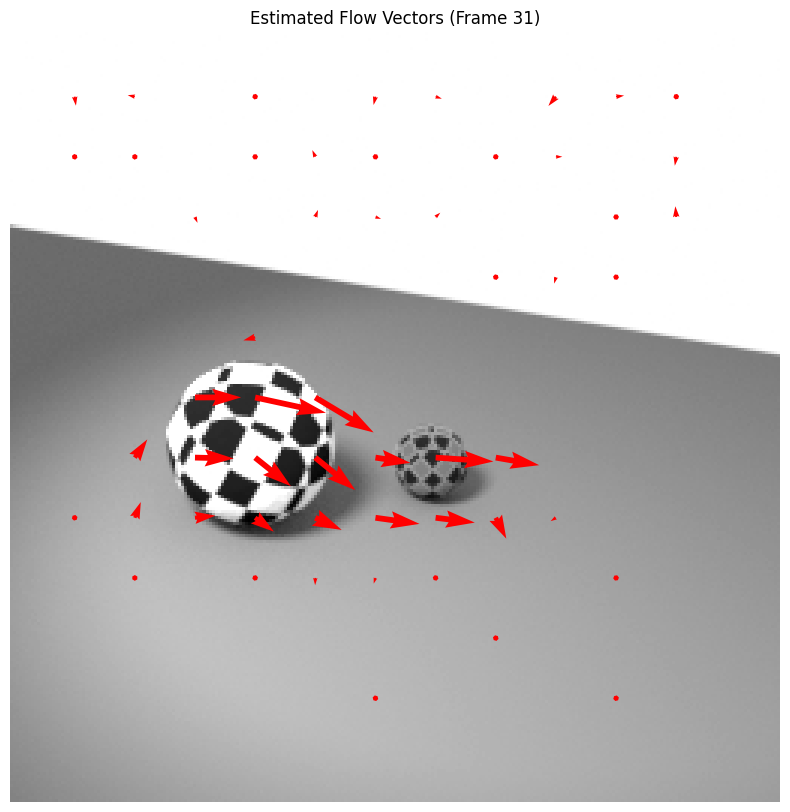

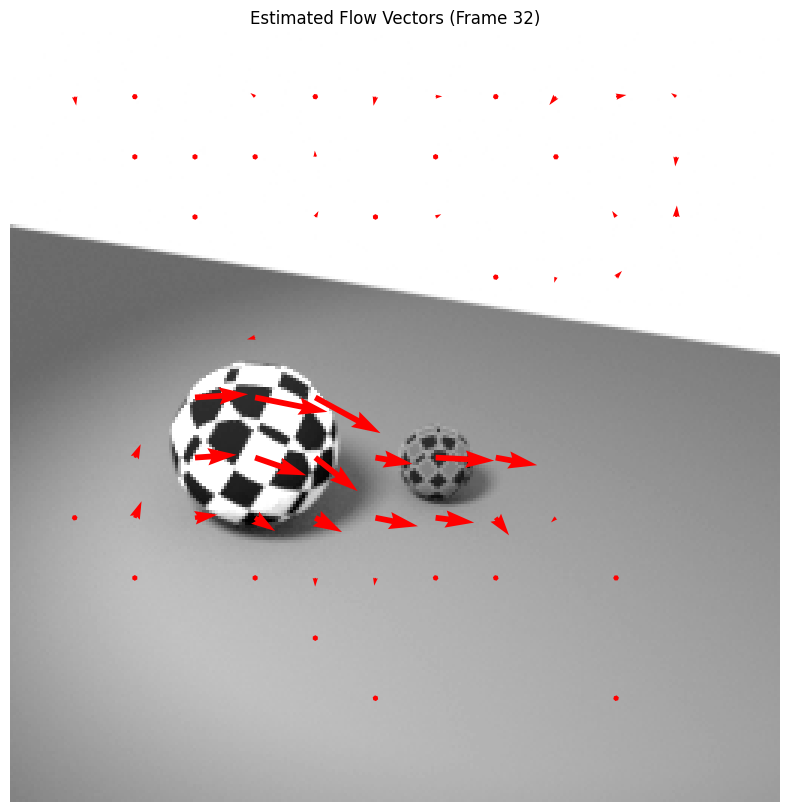

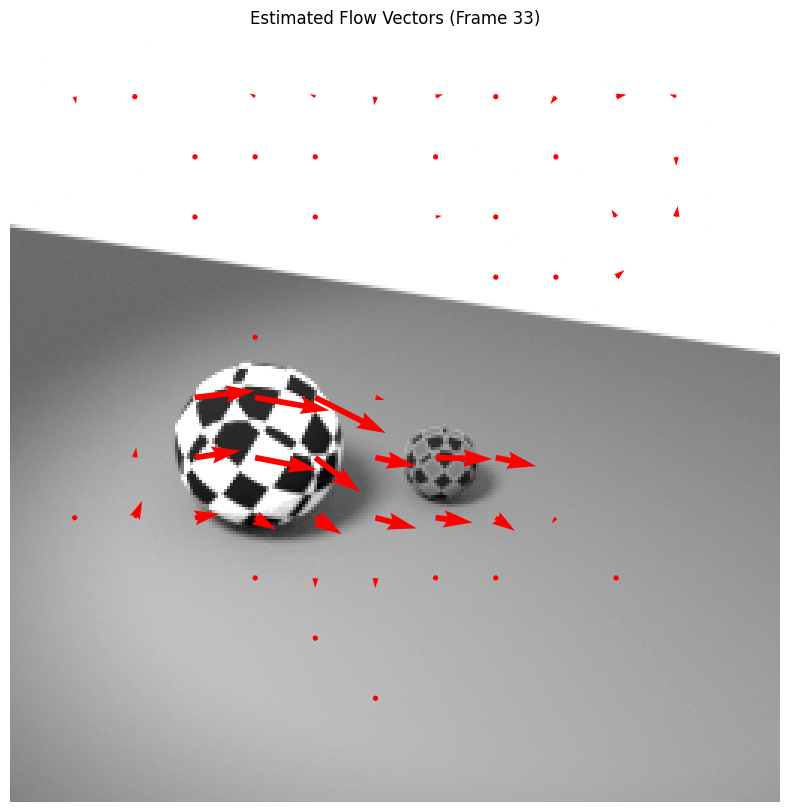

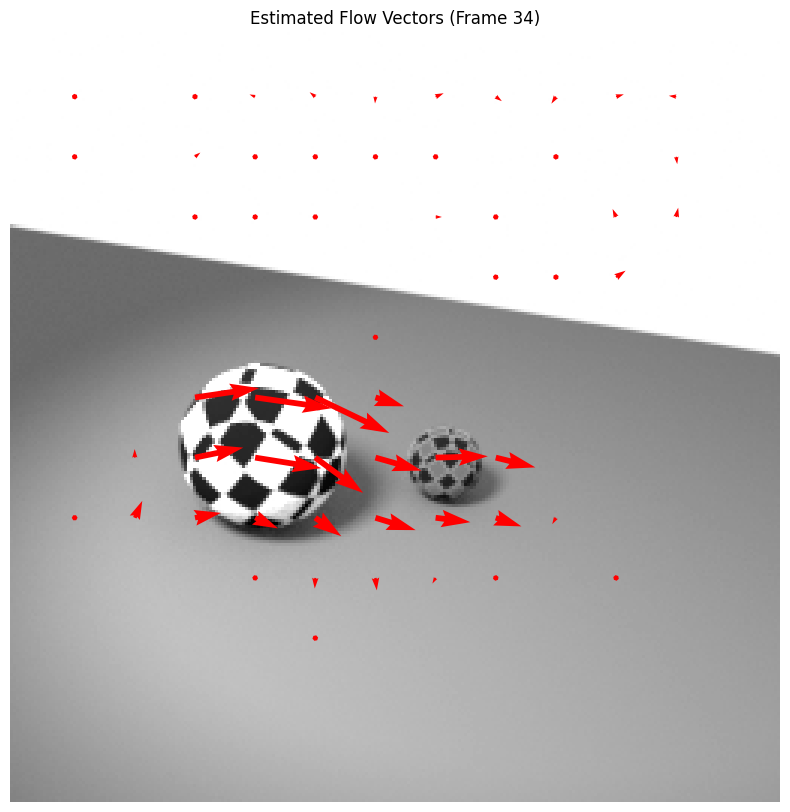

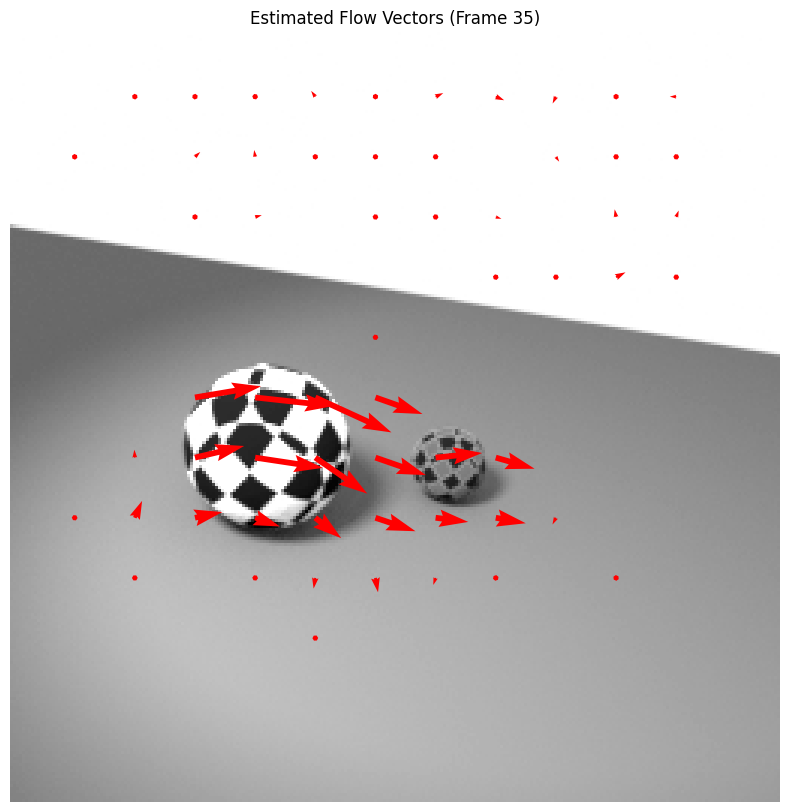

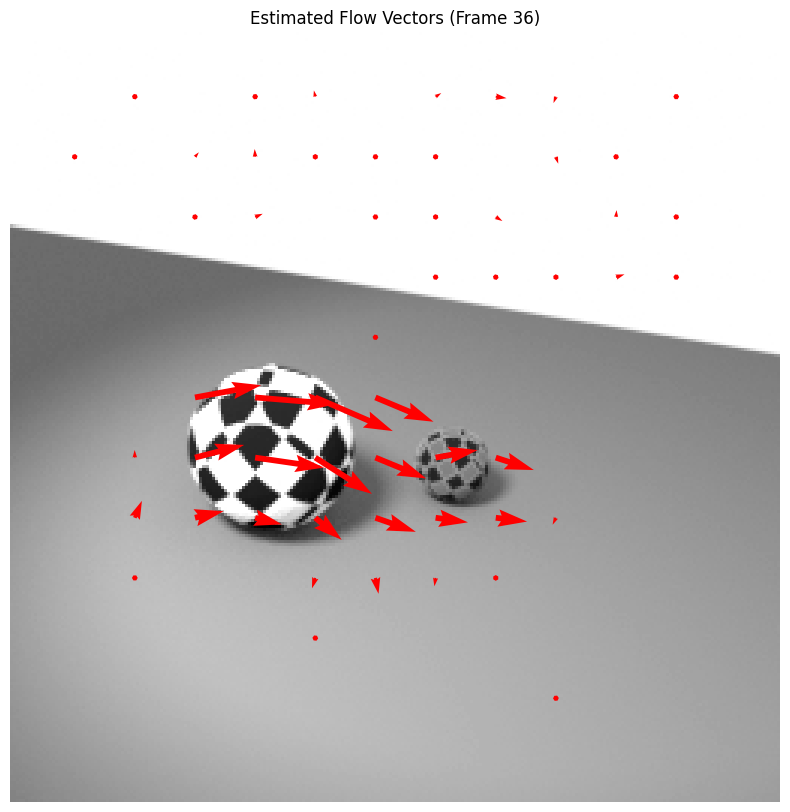

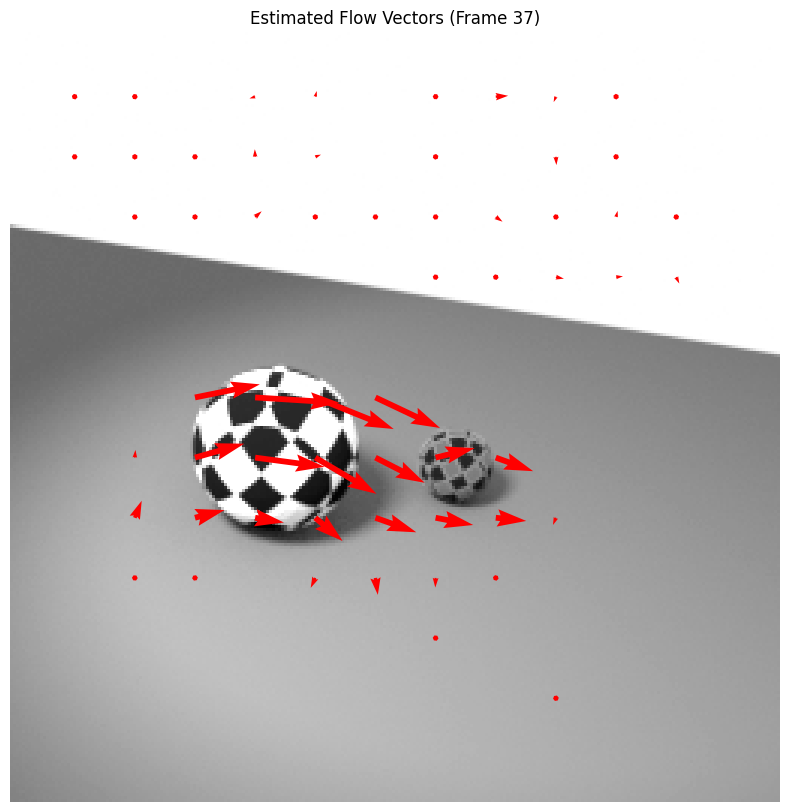

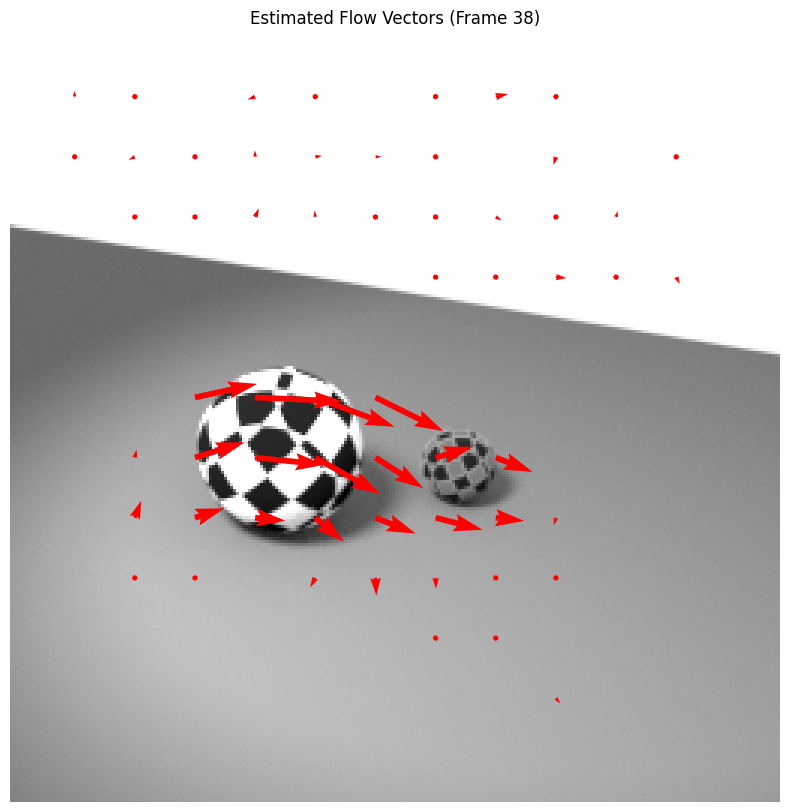

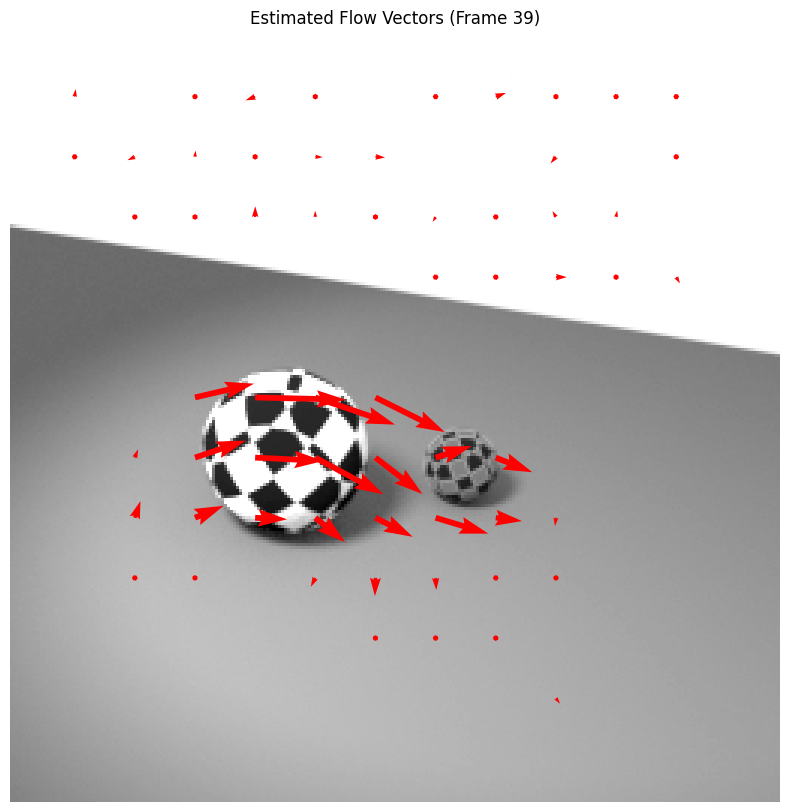

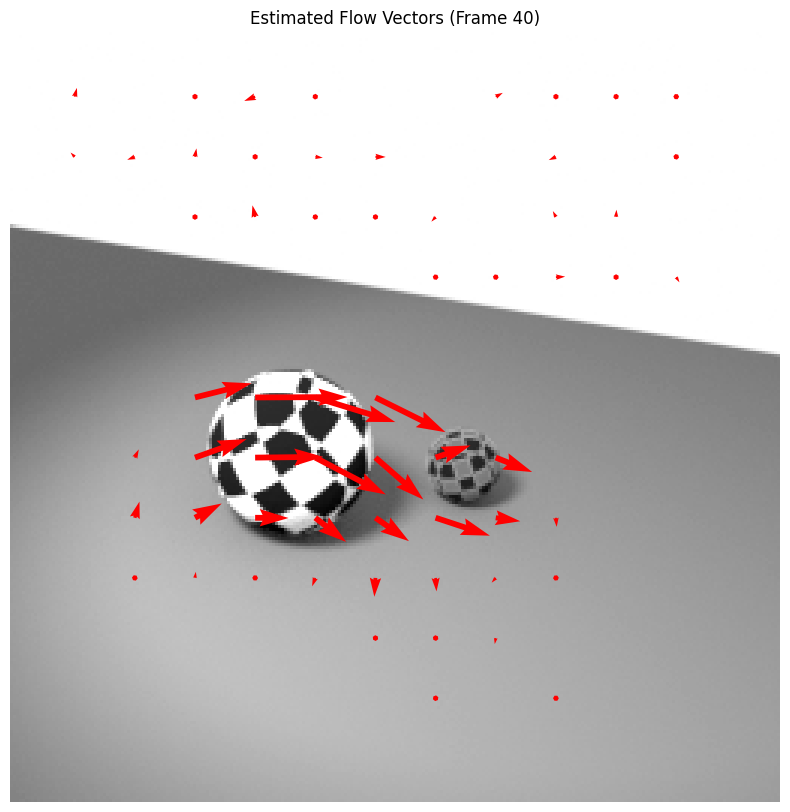

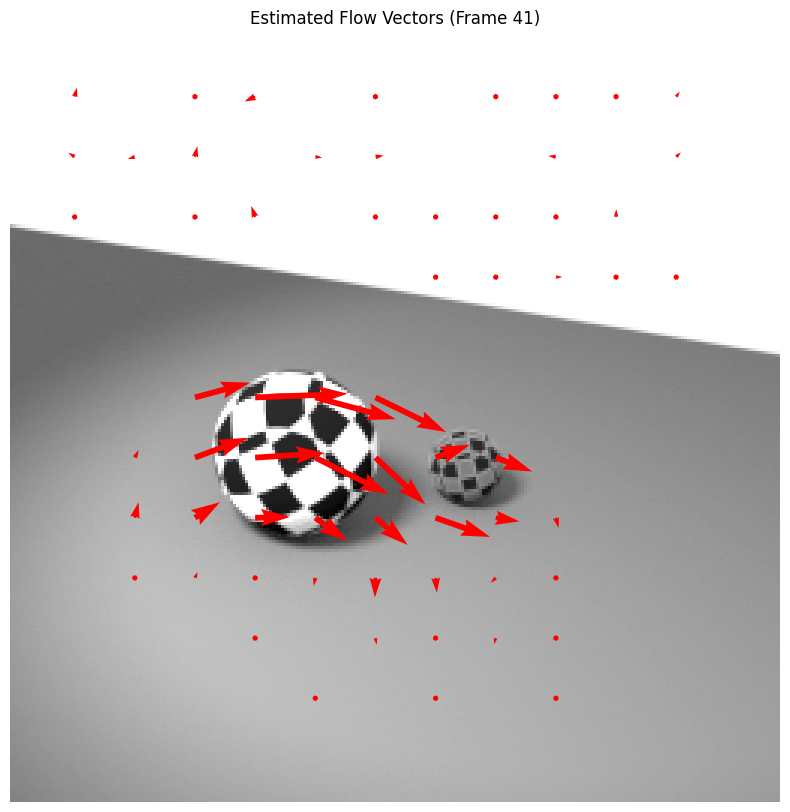

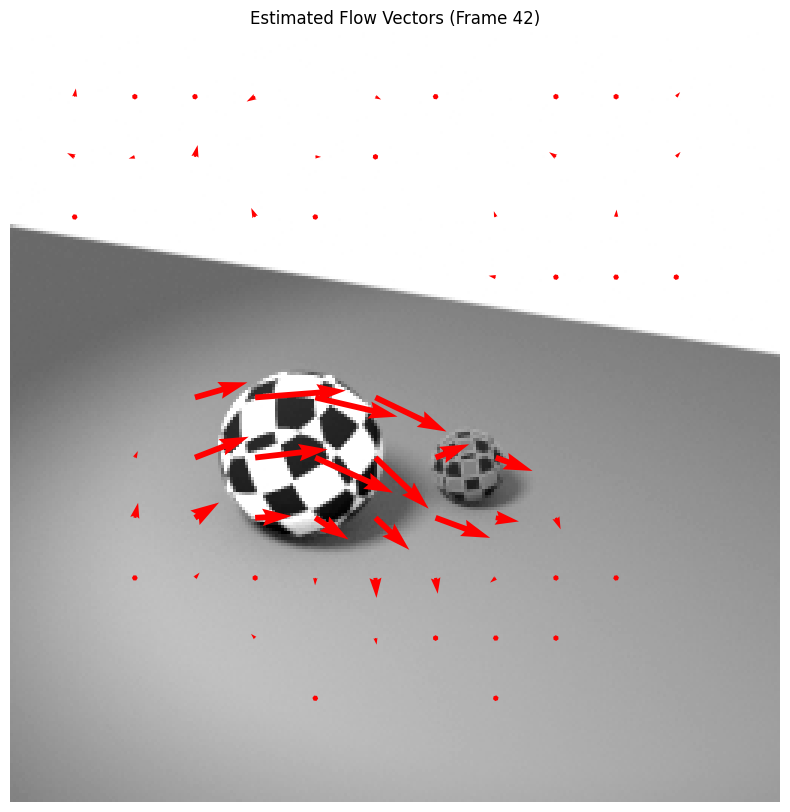

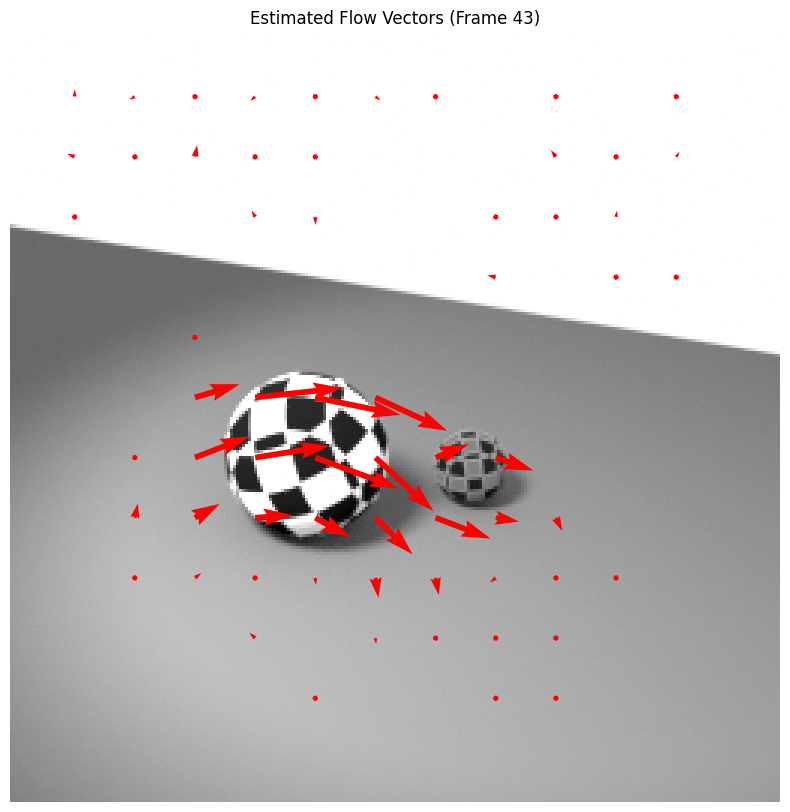

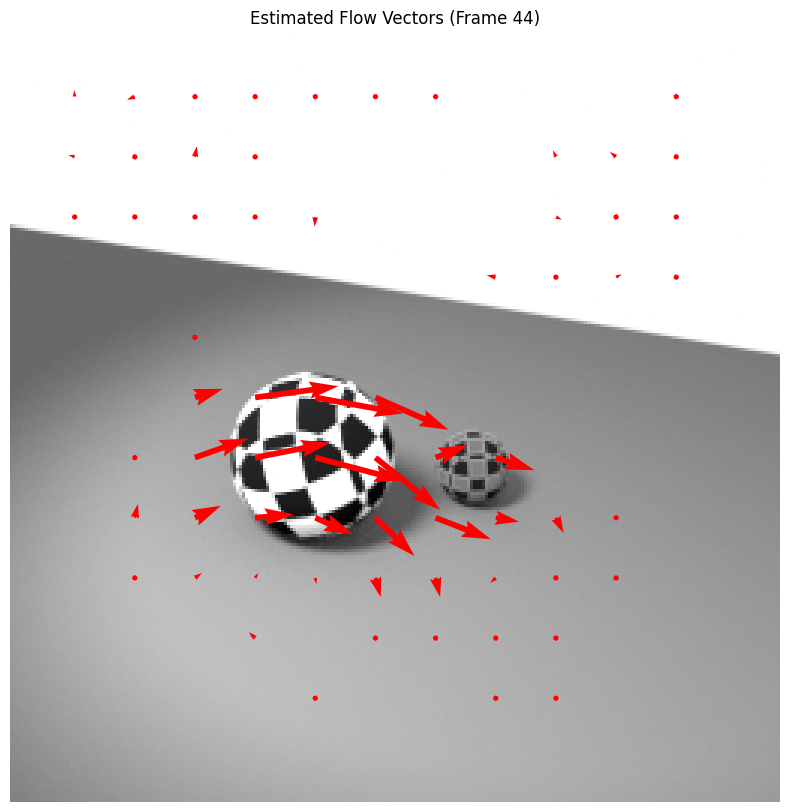

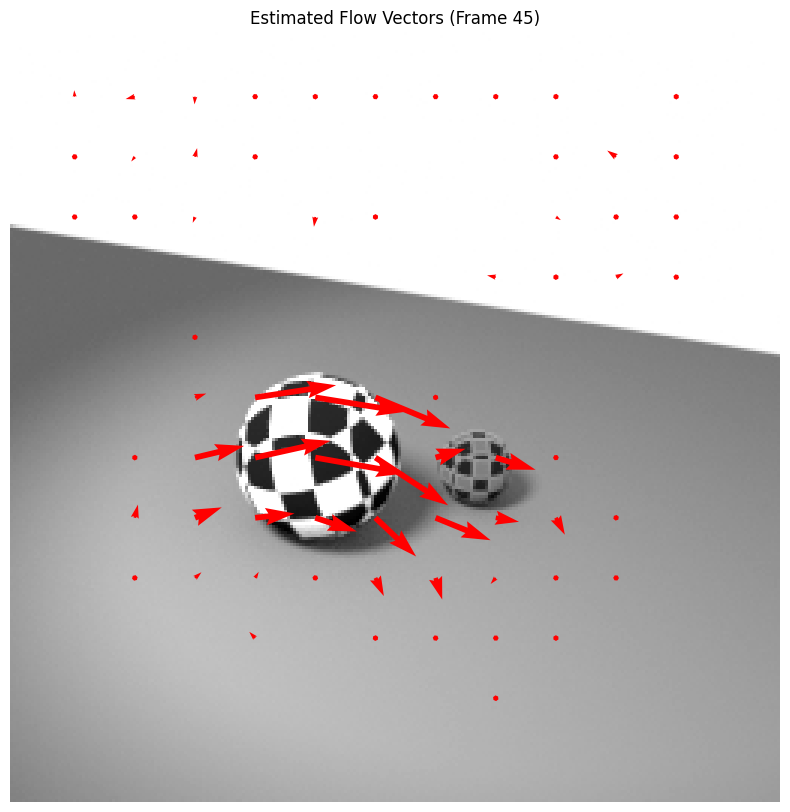

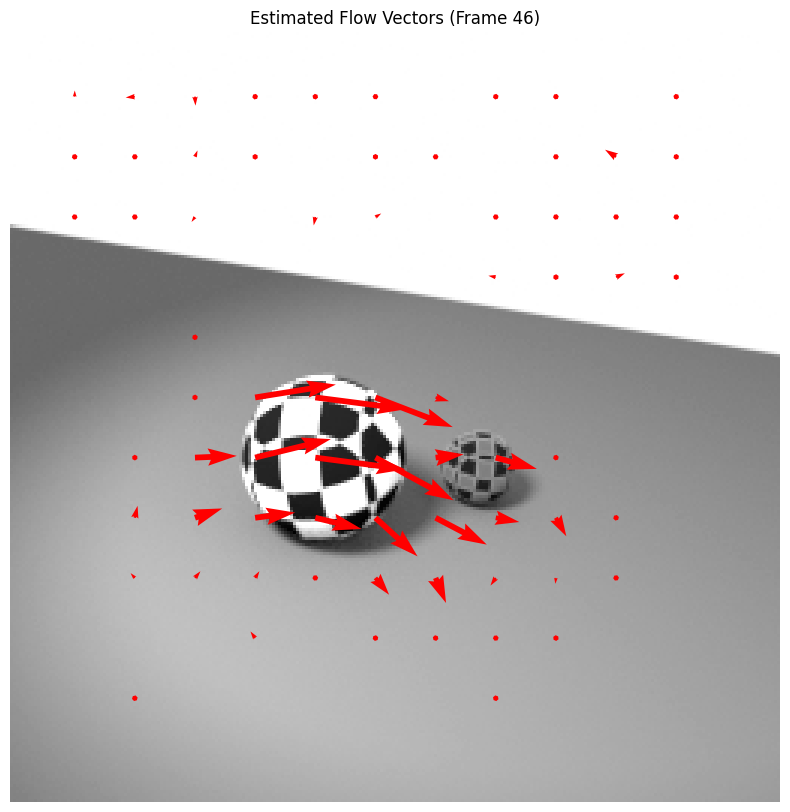

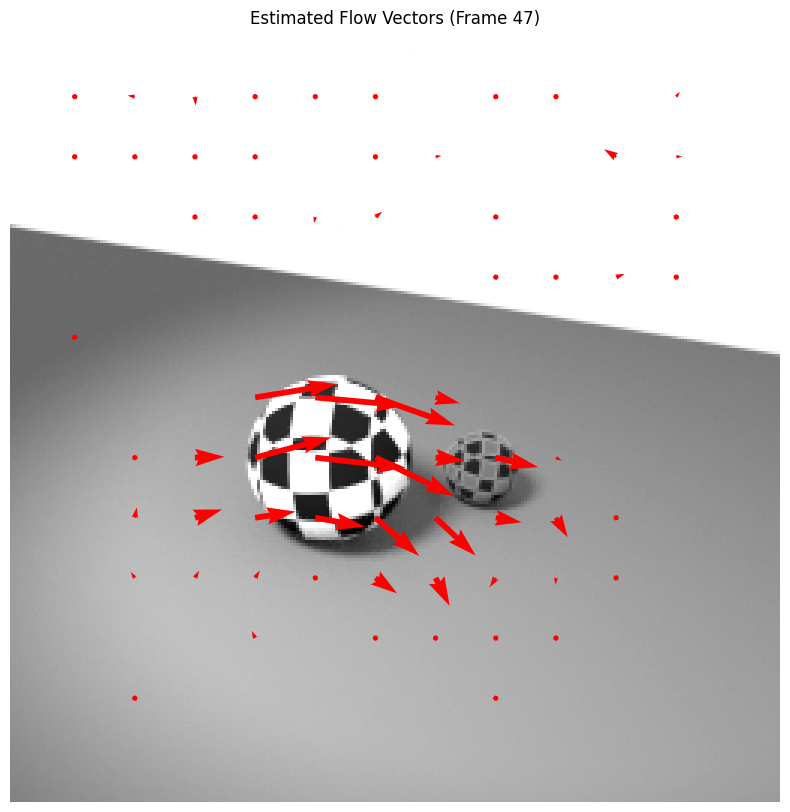

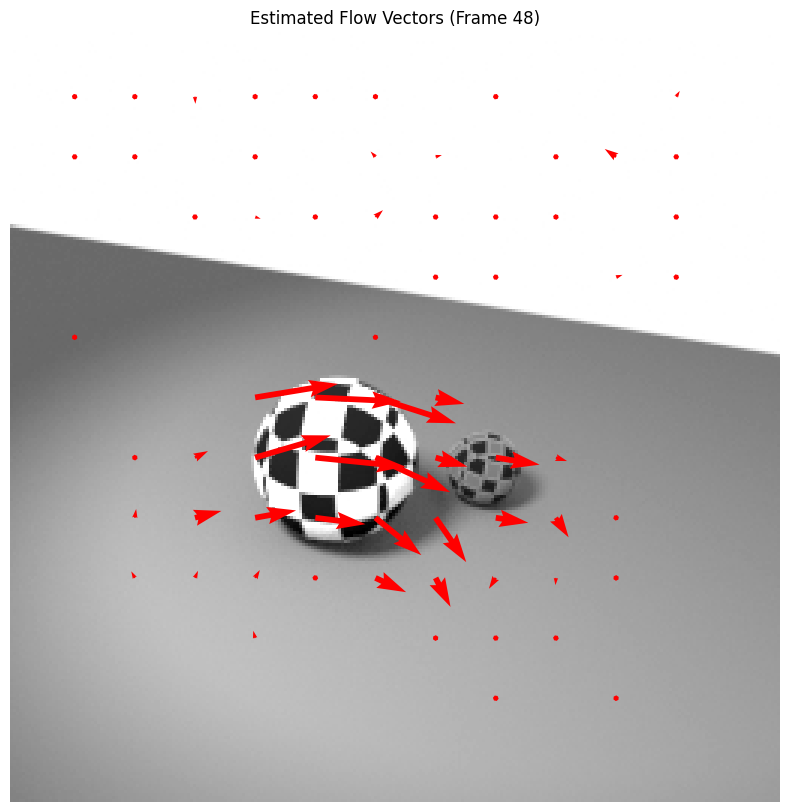

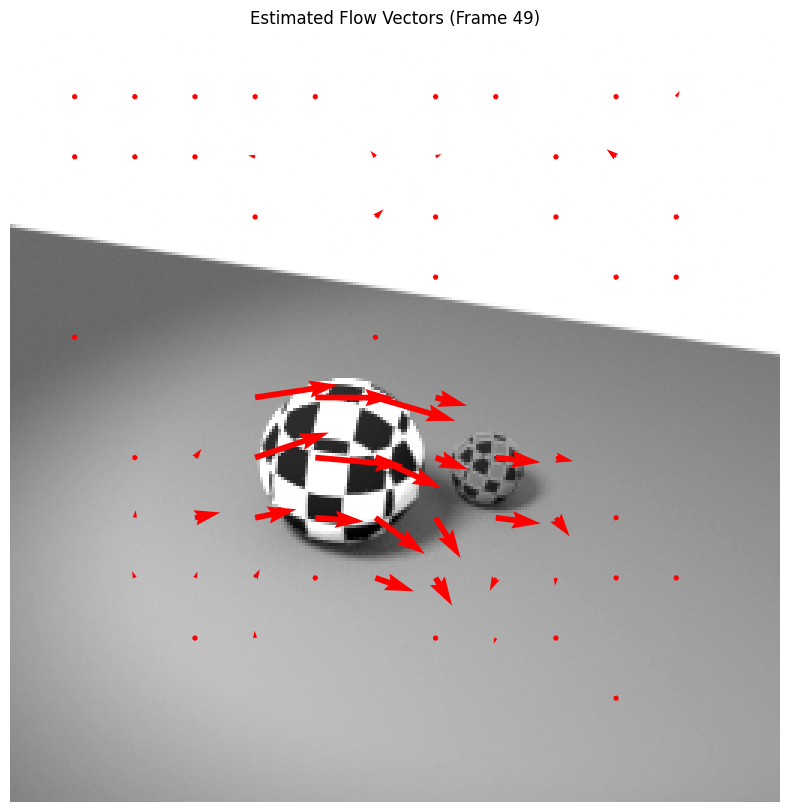

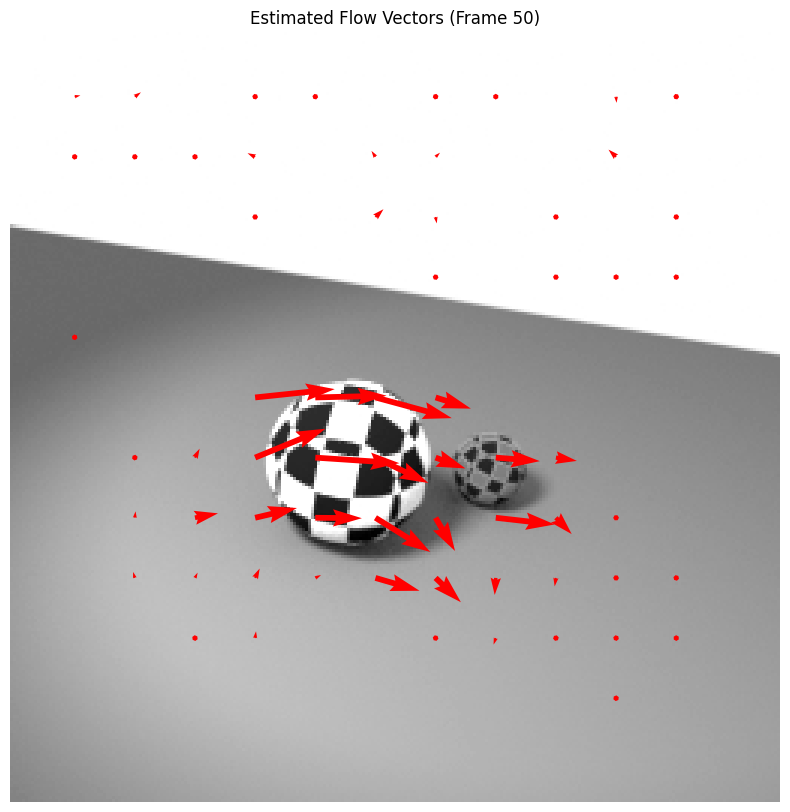

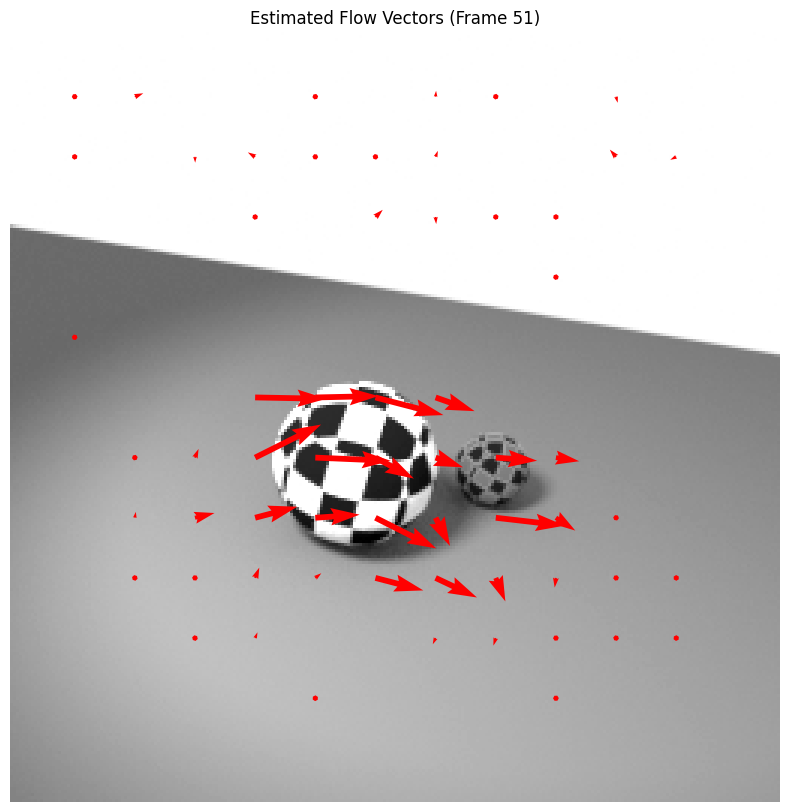

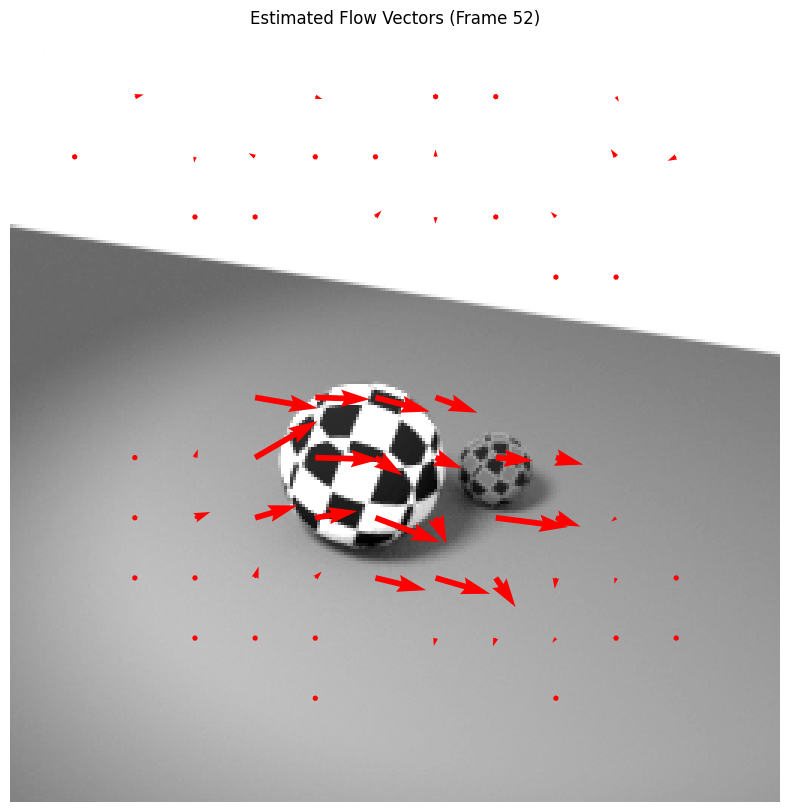

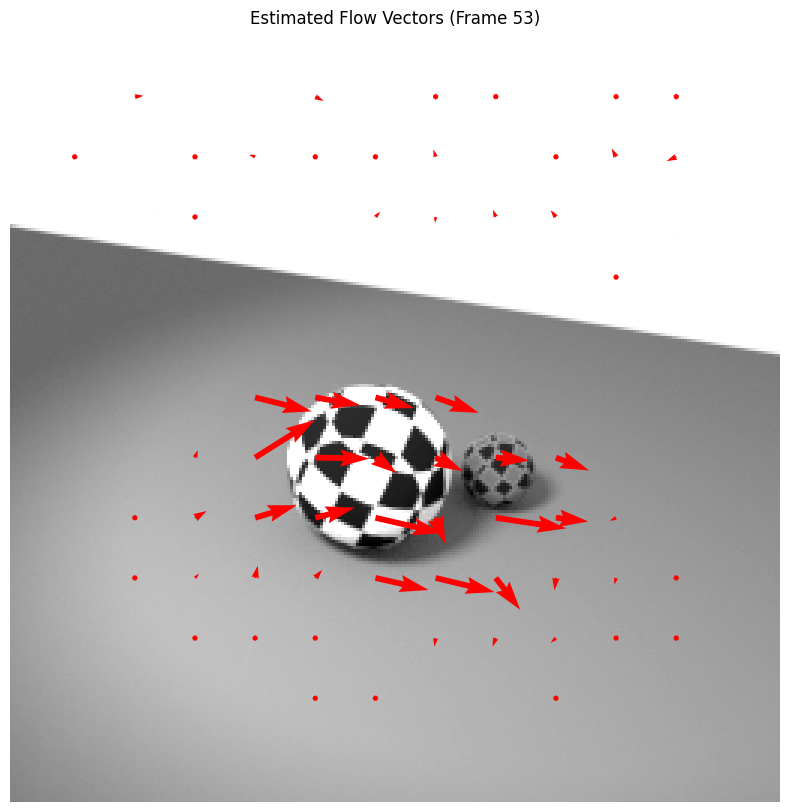

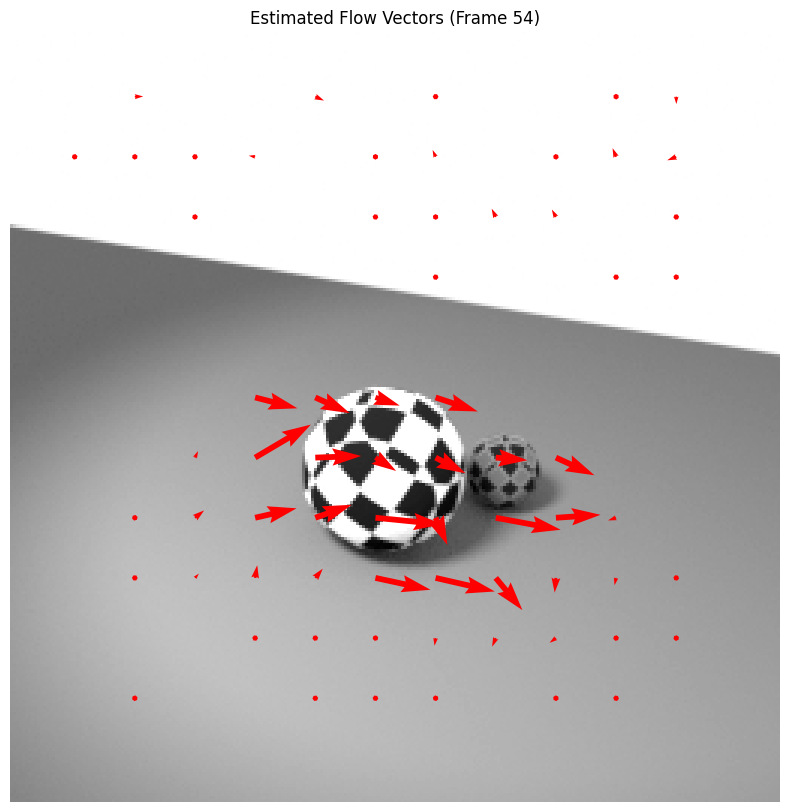

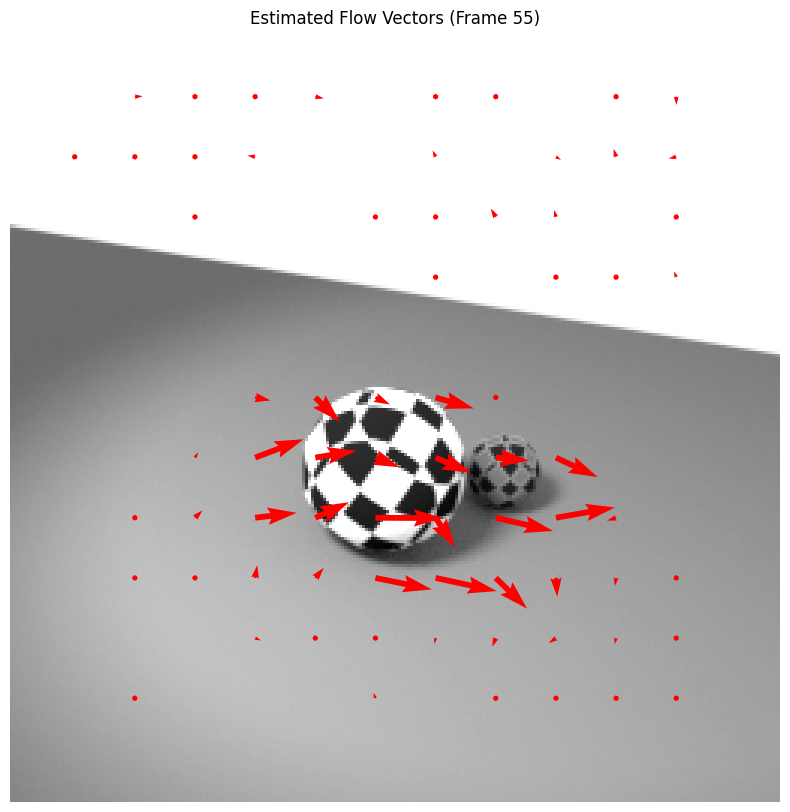

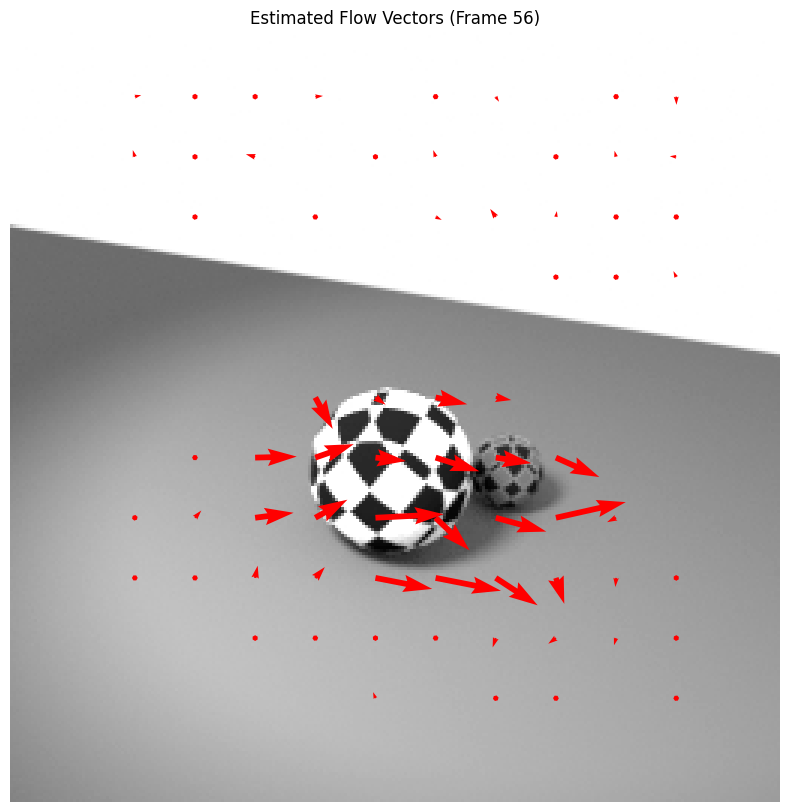

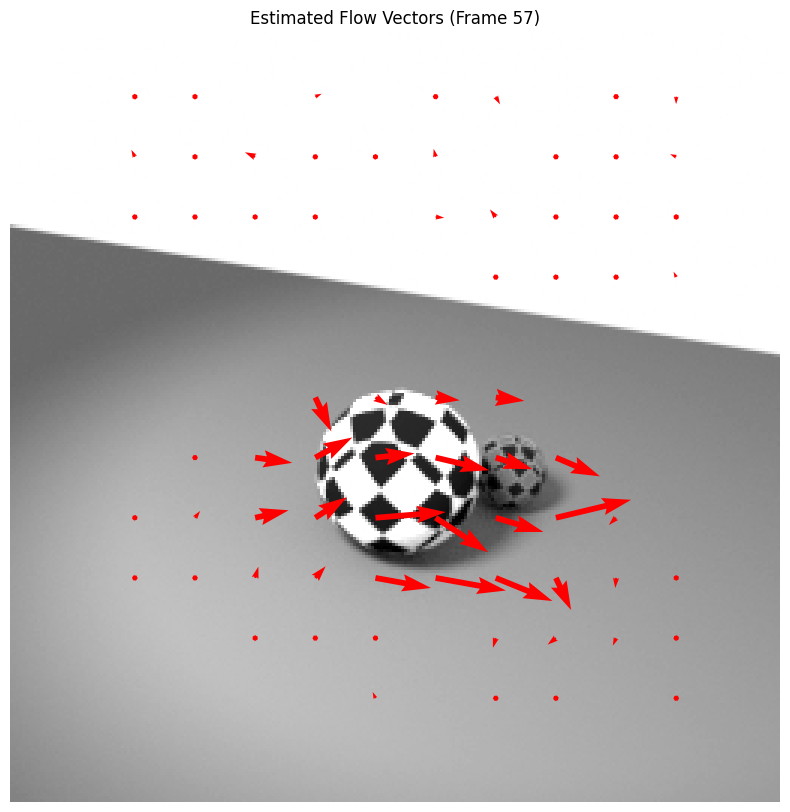

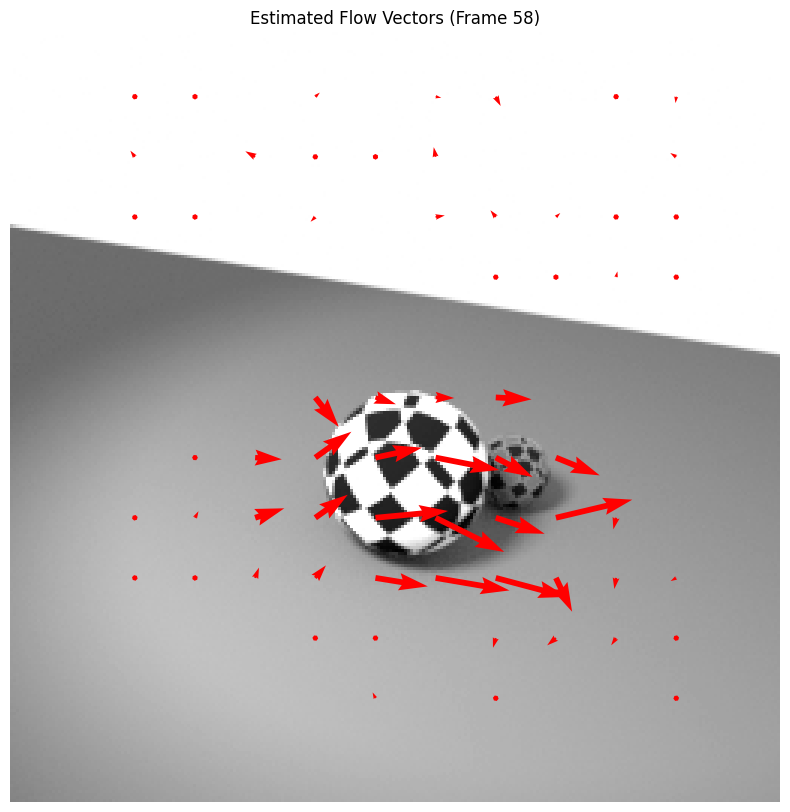

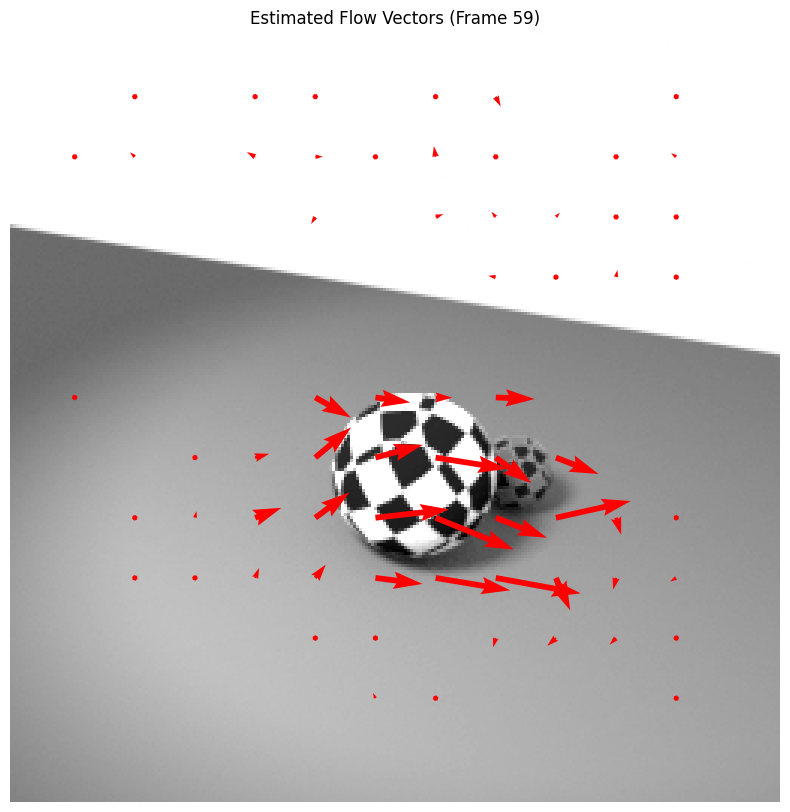

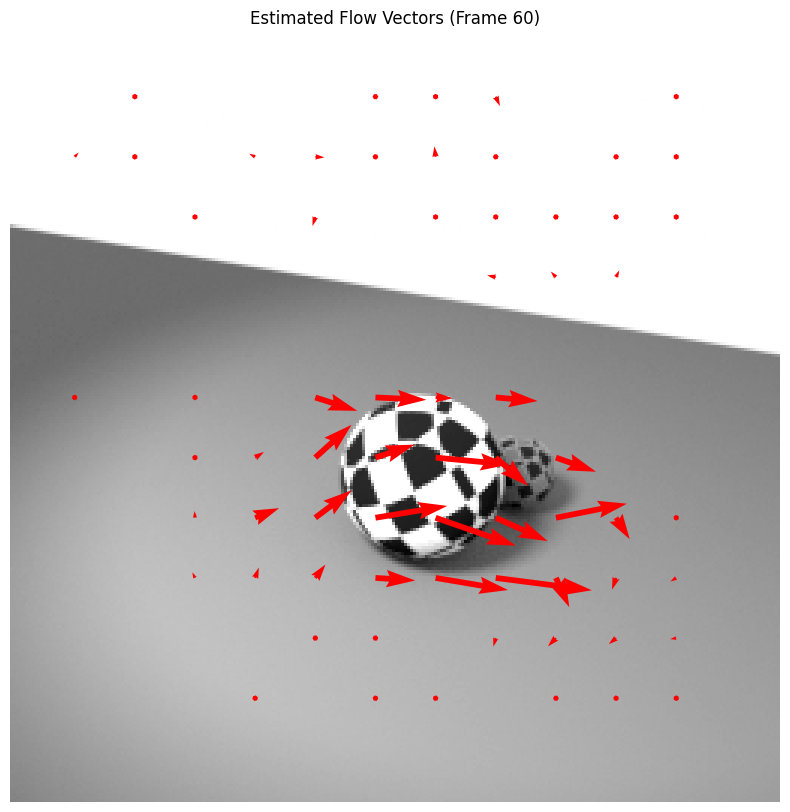

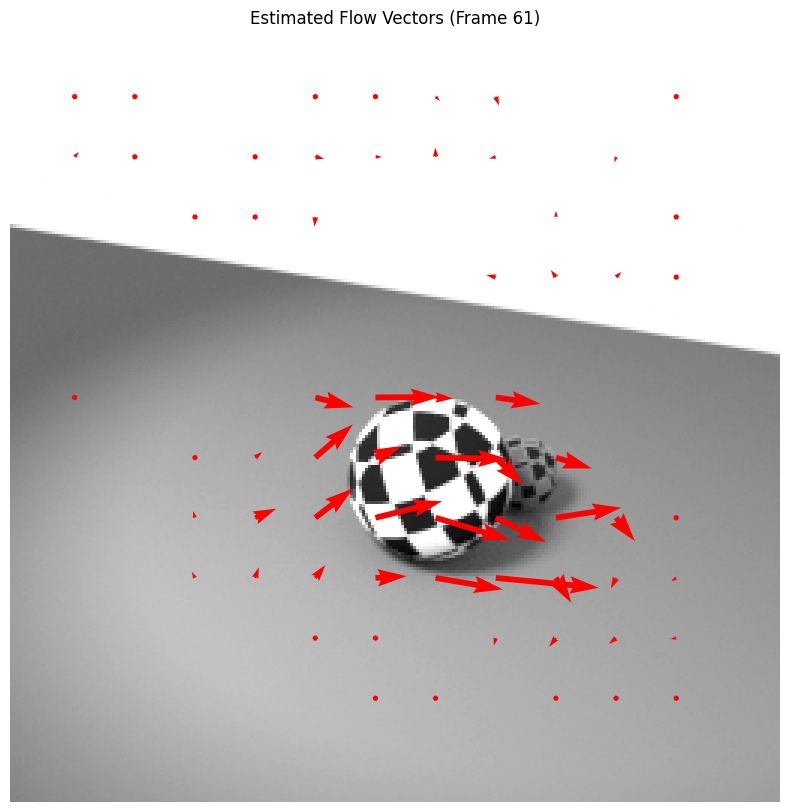

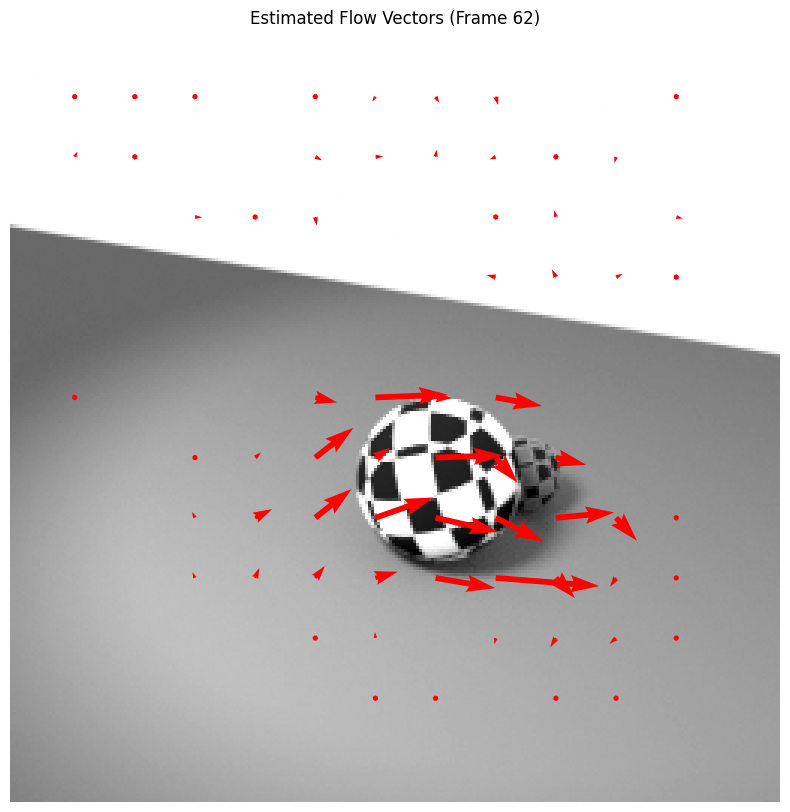

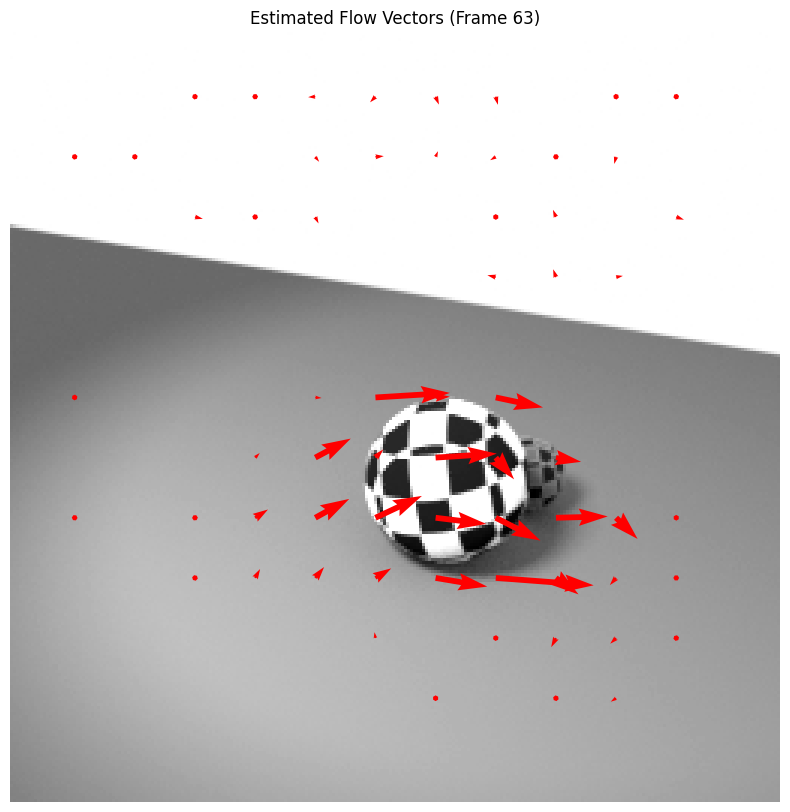

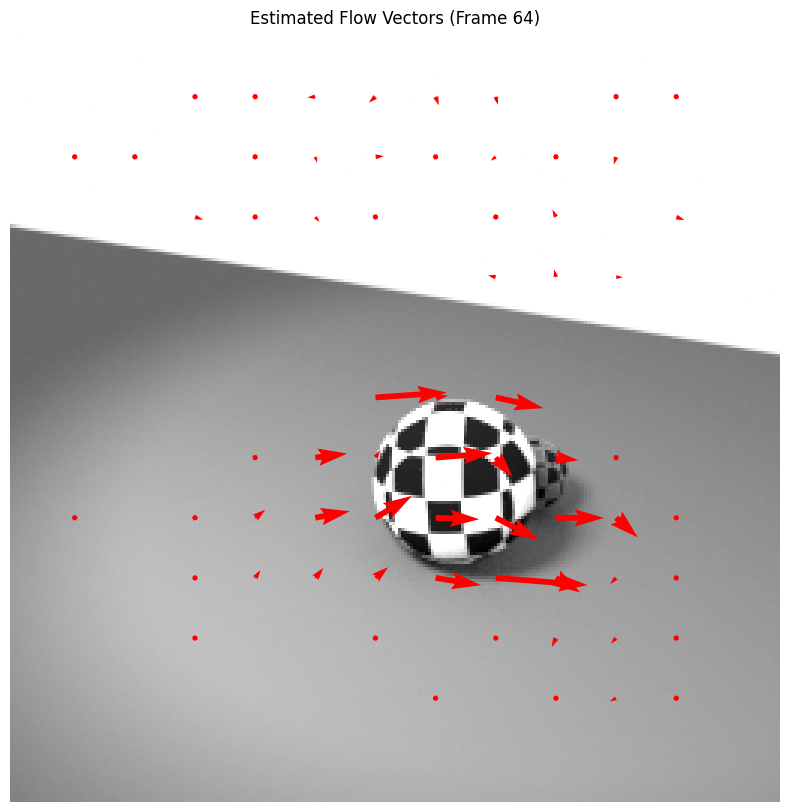

In [ ]:
# again, go through all frames and plot the flow vectors, with stride of 20

for t in range(frames.shape[0]):
    N = 21
    stride = 20
    plt.figure(figsize=(10, 10))
    plt.imshow(frames[t], cmap="gray")
    for y in range(N, frames[t].shape[0] - N, stride):
        for x in range(N, frames[t].shape[1] - N, stride):
            flow_vector = np.array([u[t, y, x], v[t, y, x]]) * 10
            if np.linalg.norm(flow_vector) < 1:  # Only plot significant flow vectors
                continue
            plt.quiver(
                x,
                y,
                flow_vector[0],
                flow_vector[1],
                color="red",
                angles="xy",
                scale_units="xy",
                scale=1,
            )
    plt.title(f"Estimated Flow Vectors (Frame {t + 1})")
    plt.axis("off")
    plt.show()

In [ ]:
from PIL.Image import new
import av

container = av.open("./videos/apenture.mp4")
downscaled_shape = (640, 360)
i = 0
for frame in container.decode(video=0):
    img = frame.to_image()  # PIL/Pillow image
    # arr = np.asarray(img)  # numpy array
    # aspect ratio is 16:9, so downscale to 160x90
    # downscale everything to 640x360
    # downscale everything to
    new_img = img.resize(downscaled_shape)
    arr = np.asarray(new_img)
    print(i)
    i += 1

    # Do something!